# Section 3 · Create quantum circuits

Exam weight: 18% of C1000-179 · about 12 of the 68 questions

## Study path

**Core first pass:** Construct and measure circuits, bind parameters, use mid-circuit measurement and if_test, and prepare ISA circuits with a preset pass manager. Understand the transpiler stages and what passes do.

- Core coding practice: **3.1–3.5 and 3.7**.
- Optional second pass: **3.6 (three-bit expression parity) and 3.8 (a custom pre_layout hook); custom-pass implementation and its marked question.**
- Core review: answer all questions without an optional label.

Run the setup cell, then work through the unmarked examples in order. Complete a practice starter before running its check cell. At an optional block, use its **continue with the core path** link to skip the entire block; the remaining core cells do not depend on it. Notebook tags `study-core` and `study-optional` also identify the two paths; ordinary **Run All** does not filter tags.

Core/optional labels set a learning priority, not a boundary on what the exam may ask. The [official objectives and sample](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400) remain the coverage reference.

**Jump to:** [Basic circuits](#s3-core-2) · [Parameters](#s3-core-33) · [Dynamic circuits](#s3-core-59) · [Transpilation](#s3-core-88) · [Review](#s3-core-120)

This is the heaviest section of the exam.

Official objectives (numbering kept throughout this notebook):

- 3.1 Construct dynamic circuits
- 3.2 Construct parameterized circuits
- 3.3 Transpile and optimize circuits
- 3.4 Construct basic quantum circuits

The parts are taught in the order 3.4 → 3.2 → 3.1 → 3.3 (basic → parameterized → dynamic → transpile), because each one builds on the previous.

Topics

- build circuits from integer sizes or named registers (including `AncillaRegister`) and choose correctly between `measure`, `measure_all` and `measure_active`
- combine circuits with `compose`, `append` and `tensor`, and predict qubit order, global phase and the layout of result bitstrings
- write parameterized circuits with `Parameter`, `ParameterVector` and parameter expressions, and bind them safely with `assign_parameters`
- add mid-circuit measurements and classical feedforward with `if_test`, `switch`, loops and `expr` conditions, and check whether a backend supports them
- turn an abstract circuit into an ISA circuit with `generate_preset_pass_manager`, explain the six stages and the four optimization levels, read the resulting layout, and customise a pass manager

Built from the Qiskit Advocate KR study notebooks `1_Construct_Dynamic_Circuits_KR`, `2_Construct_Parameterized_Circuits_KR`, `3_Transpile_Circuits`, `4_Construct_Quantum_Circuits_KR` and `Review/Practice_05_Dynamic_Circuits`, and the QAMP 2025 tutorial (links in the Sources cell at the end).

How to use: lecture cells are already executed. For each selected practice, replace the `None` / `# TODO` parts before running its check cell. Solutions and answers are folded under each item. Everything runs locally without an IBM Quantum account: circuits are executed with the Runtime `SamplerV2` on an `AerSimulator`, and fake backends serve as transpilation targets. The primitives themselves are covered in depth in Sections 4–6.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, AncillaRegister, transpile
from qiskit.circuit import Parameter, ParameterVector
from qiskit.circuit.classical import expr
from qiskit.circuit.library import HGate, CXGate, ZGate, QFTGate, real_amplitudes, zz_feature_map
from qiskit.quantum_info import Statevector, Operator
from qiskit.transpiler import generate_preset_pass_manager, PassManager, StagedPassManager, CouplingMap
from qiskit.transpiler.passes import InverseCancellation, Optimize1qGatesDecomposition
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeManilaV2, FakeLimaV2, FakeTorino

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

# One execution pattern for the whole notebook: the Runtime SamplerV2 on a local, ideal AerSimulator.
# AerSimulator also executes mid-circuit measurements and control flow (Part 3.1).
SIM = AerSimulator()
sim_pm = generate_preset_pass_manager(optimization_level=0, backend=SIM)   # unrolls custom instructions
sampler = SamplerV2(mode=SIM)
sampler.options.simulator.seed_simulator = 2026

def run_counts(circuit, shots=1000):
    # joint counts over all classical registers: last register leftmost, bit 0 of each register rightmost
    pub_result = sampler.run([sim_pm.run(circuit)], shots=shots).result()[0]
    return pub_result.join_data().get_counts()

def probs(circuit, decimals=3):
    # exact outcome probabilities of a measurement-free circuit
    return {str(k): round(float(v), decimals) for k, v in Statevector(circuit).probabilities_dict().items()}

qiskit 2.0.3 | qiskit-aer 0.17.1 | qiskit-ibm-runtime 0.40.1


<a id="s3-core-2"></a>

## 3.4 Construct basic quantum circuits

### Bits, registers and constructors

A `QuantumCircuit` owns bits — `Qubit` and `Clbit` objects — that can be grouped into named registers:
`QuantumRegister`, `ClassicalRegister`, and `AncillaRegister` (a quantum register flagged as helper qubits; ancillas are ordinary qubits that are also counted in `num_ancillas`).

| Constructor | What you get |
|---|---|
| `QuantumCircuit(3)` | 3 qubits in a register named `q`, no classical bits |
| `QuantumCircuit(3, 2)` | registers `q` (3 qubits) and `c` (2 clbits) |
| `QuantumCircuit(qr, anc, cr, ...)` | any registers, bits ordered in the order the registers are passed |
| `QuantumCircuit(2, name="bell", global_phase=np.pi/2)` | keyword options: circuit name, global phase, `metadata` |
| `QuantumCircuit()` then `qc.add_register(QuantumRegister(2, "r"))` | start empty, add registers later |

Registers created without a name get automatic names (`q0`, `q1`, `c0`, …, taken from a global counter), so give names to registers you want to recognise in drawings and counts.

In [2]:
data = QuantumRegister(3, "data")
anc = AncillaRegister(1, "anc")
out = ClassicalRegister(3, "out")
qc = QuantumCircuit(data, anc, out, name="demo")

print("qregs      :", qc.qregs)
print("cregs      :", qc.cregs)
print("num_qubits :", qc.num_qubits, "| num_ancillas:", qc.num_ancillas, "| num_clbits:", qc.num_clbits)
print("width      :", qc.width(), "(qubits + clbits)")
print("find_bit(anc[0]) ->", qc.find_bit(anc[0]))
print("find_bit(out[2]) ->", qc.find_bit(out[2]))

qregs      : [QuantumRegister(3, 'data'), QuantumRegister(1, 'anc')]
cregs      : [ClassicalRegister(3, 'out')]
num_qubits : 4 | num_ancillas: 1 | num_clbits: 3
width      : 7 (qubits + clbits)
find_bit(anc[0]) -> BitLocations(index=3 registers=[(QuantumRegister(1, 'anc'), 0)])
find_bit(out[2]) -> BitLocations(index=2 registers=[(ClassicalRegister(3, 'out'), 2)])


Indexing. Gate methods accept an integer (position in `qc.qubits` / `qc.clbits`), a `Qubit`/`Clbit` object (`data[1]`), or a register, slice or list — in which case the call is broadcast. `qc.find_bit(bit)` goes the other way: from a bit object to its integer index and the registers that contain it. Each entry of `qc.data` is a `CircuitInstruction` with `.operation`, `.qubits` and `.clbits`.

In [3]:
qc = QuantumCircuit(QuantumRegister(3, "q"), ClassicalRegister(3, "c"))
qc.h(0)                              # integer index
qc.cx(qc.qubits[0], [1, 2])          # one control, list of targets -> two CX gates
qc.barrier()                         # no arguments: all qubits
qc.measure([0, 1, 2], [2, 1, 0])     # pairwise: q0->c2, q1->c1, q2->c0
print(qc.draw(fold=-1))

for inst in qc.data[:3]:
    print(inst.operation.name, [qc.find_bit(q).index for q in inst.qubits])

     ┌───┐           ░ ┌─┐      
q_0: ┤ H ├──■────■───░─┤M├──────
     └───┘┌─┴─┐  │   ░ └╥┘┌─┐   
q_1: ─────┤ X ├──┼───░──╫─┤M├───
          └───┘┌─┴─┐ ░  ║ └╥┘┌─┐
q_2: ──────────┤ X ├─░──╫──╫─┤M├
               └───┘ ░  ║  ║ └╥┘
c: 3/═══════════════════╩══╩══╩═
                        2  1  0 
h [0]
cx [0, 1]
cx [0, 2]


### Circuit metrics

| Method | Counts | Barrier? |
|---|---|---|
| `qc.size()` | number of instructions (gates, measurements, resets, …) | not counted |
| `qc.depth()` | length of the critical path, in layers | not counted as a layer, but still orders the operations around it |
| `qc.count_ops()` | `{name: count}` for every instruction | listed |
| `len(qc.data)` | raw number of `CircuitInstruction` entries | counted |
| `qc.width()` | `num_qubits + num_clbits` | – |
| `qc.num_nonlocal_gates()` | gates on two or more qubits | – |

In [4]:
print("size :", qc.size(), "| depth:", qc.depth(), "| len(data):", len(qc.data))
print("ops  :", dict(qc.count_ops()), "| 2q gates:", qc.num_nonlocal_gates())

size : 6 | depth: 4 | len(data): 7
ops  : {'measure': 3, 'cx': 2, 'h': 1, 'barrier': 1} | 2q gates: 2


`size()` and `depth()` skip barriers, but measurements and resets are counted. A barrier is not a layer of its own, yet it still acts as a fence: a gate placed after it cannot slide into an earlier layer.

### Measurement: `measure`, `measure_all`, `measure_active`

| Call | Classical bits used | Notes |
|---|---|---|
| `qc.measure(qubits, clbits)` | clbits you name | pairwise broadcast; both lists must have the same length |
| `qc.measure_all()` | adds a new register `meas` with one bit per qubit | inserts a barrier first; `add_bits=False` reuses existing clbits instead (needs `num_clbits >= num_qubits`); `inplace=False` returns a copy |
| `qc.measure_active()` | adds a register `meas` sized to the non-idle qubits | idle qubits are not measured |
| `qc.remove_final_measurements()` | removes final measurements, final barriers and classical registers that become unused | useful before `Statevector(qc)` |

`SamplerV2` returns one field per classical register: after `measure_all()` the outcomes are in `result[0].data.meas`, a register named `c` is `result[0].data.c`. `result[0].join_data().get_counts()` joins all registers into one bitstring with the last register on the left; inside each register bit 0 is the rightmost character. (The older `backend.run(...).result().get_counts()` path prints the same bits with a space between registers, e.g. `'011 00'`.)

In [5]:
ghz = QuantumCircuit(3, 2)          # register c (2 bits) already exists
ghz.h(0)
ghz.cx(0, 1)                        # qubit 2 stays idle

m_all = ghz.measure_all(inplace=False)
m_act = ghz.measure_active(inplace=False)
print("measure_all    :", [(r.name, r.size) for r in m_all.cregs])
print("measure_active :", [(r.name, r.size) for r in m_act.cregs], run_counts(m_act))

res = sampler.run([sim_pm.run(m_all)], shots=1000).result()[0]    # one PubResult per circuit
print("measure_all -> data.meas:", res.data.meas.get_counts(), "| data.c:", res.data.c.get_counts())
print("               joined   :", res.join_data().get_counts())

reuse = QuantumCircuit(2, 2)
reuse.h(0)
reuse.cx(0, 1)
reuse.measure_all(add_bits=False)   # writes into the existing c[0], c[1]
print("add_bits=False :", [(r.name, r.size) for r in reuse.cregs], run_counts(reuse))

measure_all    : [('c', 2), ('meas', 3)]
measure_active : [('c', 2), ('meas', 2)] {'1100': 496, '0000': 504}
measure_all -> data.meas: {'011': 504, '000': 496} | data.c: {'00': 1000}
               joined   : {'01100': 504, '00000': 496}
add_bits=False : [('c', 2)] {'11': 496, '00': 504}


Calling `measure_all()` on a circuit that already has a classical register adds a second register. With `SamplerV2` the outcomes are in `data.meas`, while `data.c` holds only zeros (and every joined bitstring ends in `00`). Use `measure_all(add_bits=False)` or explicit `measure(...)` if you want the existing bits.

Q3.1. What does this code print?

```python
qc = QuantumCircuit(3, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()
print(qc.num_clbits, [c.name for c in qc.cregs])
```

A. `2 ['c']`

B. `3 ['meas']`

C. `5 ['c', 'meas']`

D. It raises `CircuitError` because the circuit has fewer classical bits than qubits.

<details>
<summary>Show answer</summary>

Answer: C

`measure_all()` defaults to `add_bits=True`: it keeps register `c` (2 bits) and adds a new register `meas` with one bit per qubit (3), so there are 5 clbits. The error in D only happens with `measure_all(add_bits=False)`, which needs at least as many clbits as qubits. B describes `measure_all` on a circuit with no classical register.

</details>

### Reset and barrier

- `qc.reset(q)` returns a qubit to $|0\rangle$ in the middle of a circuit. It is not unitary, so a circuit containing it cannot become a `Gate`.
- `qc.barrier(...)` has no effect on the state. It groups the drawing and stops the transpiler from optimizing across it (you will see this in Part 3.3).

In [6]:
rs = QuantumCircuit(1, 1)
rs.x(0)
rs.reset(0)          # |1> -> |0>
rs.measure(0, 0)
print(run_counts(rs))

{'0': 1000}


### State preparation: `initialize` vs `prepare_state`

Both accept a `Statevector` or list of amplitudes, a label string (`'01'`, `'+-'`, `'rl'`), or an integer (its binary expansion). Labels are little-endian: the rightmost character is qubit 0.

| | `qc.initialize(state, qubits)` | `qc.prepare_state(state, qubits)` |
|---|---|---|
| Starts with `reset` on the target qubits | yes | no (assumes they are in $\lvert 0\rangle$) |
| Operation type | `Initialize` (non-unitary `Instruction`) | `StatePreparation` (`Gate`) |
| `inverse()` / `to_gate()` / `control()` | raise | work |
| Non-normalized amplitudes | error unless `normalize=True` | error unless `normalize=True` |

In [7]:
init = QuantumCircuit(2); init.initialize("01")
prep = QuantumCircuit(2); prep.prepare_state("01")
print("initialize('01')    ->", dict(init.decompose().count_ops()), probs(init))
print("prepare_state('01') ->", dict(prep.decompose().count_ops()), probs(prep))

amp = QuantumCircuit(2); amp.initialize([1, 0, 0, 1], normalize=True)   # Bell state from amplitudes
num = QuantumCircuit(3); num.initialize(6)                               # 6 = 0b110
print("amplitudes [1,0,0,1] ->", probs(amp))
print("integer 6            ->", probs(num))

initialize('01')    -> {'reset': 2, 'state_preparation': 1} {'01': 1.0}
prepare_state('01') -> {'x': 1} {'01': 1.0}
amplitudes [1,0,0,1] -> {'00': 0.5, '11': 0.5}
integer 6            -> {'110': 1.0}


`initialize('01')` puts qubit 0 in $|1\rangle$ and qubit 1 in $|0\rangle$ (rightmost character = qubit 0). The same rule applies to `Statevector.from_label`, counts keys and `initialize(integer)`.

### Combining circuits: `compose`, `append`, `tensor`

| Method | Modifies the caller? | Returns | Key points |
|---|---|---|---|
| `a.compose(b, qubits=[...], clbits=[...], front=False, inplace=False)` | no (default) | new circuit | `b`'s qubit i goes to `qubits[i]`; `front=True` puts `b` before `a`; `b` may not have more qubits than `a` |
| `a.append(op, qargs, cargs)` | yes | `InstructionSet` | `op` is a gate / instruction; a `QuantumCircuit` is wrapped into one opaque instruction named after the circuit |
| `a.tensor(b)` | no (default) | new circuit with `a.num_qubits + b.num_qubits` qubits | `b` goes on the lower qubits, as in $A \otimes B$ |
| `qc.to_gate()` / `qc.to_instruction()` | – | `Gate` / `Instruction` | `to_gate` needs a purely unitary circuit (no clbits, measurements, resets or barriers) |
| `qc.inverse()`, `qc.copy()`, `qc.copy_empty_like()` | – | new circuit | `other = qc` is only an alias; use `qc.copy()` for an independent copy |

In [8]:
base = QuantumCircuit(3); base.x(2)
sub = QuantumCircuit(2, name="sub"); sub.h(0); sub.cx(0, 1)

after = base.compose(sub, qubits=[2, 1])               # sub.q0 -> 2, sub.q1 -> 1
before = base.compose(sub, qubits=[2, 1], front=True)  # same mapping, sub first
print(after.draw()); print(before.draw())
print("base still has", base.size(), "instruction(s): compose returned new circuits")

wrapped = QuantumCircuit(3)
wrapped.append(sub, [0, 2])                            # one opaque instruction called 'sub'
print(wrapped.draw())
print("after decompose():", dict(wrapped.decompose().count_ops()))

xq = QuantumCircuit(1); xq.x(0)
hq = QuantumCircuit(1); hq.h(0)
print(xq.tensor(hq).draw())                            # H on qubit 0, X on qubit 1

                    
q_0: ───────────────
               ┌───┐
q_1: ──────────┤ X ├
     ┌───┐┌───┐└─┬─┘
q_2: ┤ X ├┤ H ├──■──
     └───┘└───┘     
                    
q_0: ───────────────
          ┌───┐     
q_1: ─────┤ X ├─────
     ┌───┐└─┬─┘┌───┐
q_2: ┤ H ├──■──┤ X ├
     └───┘     └───┘
base still has 1 instruction(s): compose returned new circuits
     ┌──────┐
q_0: ┤0     ├
     │      │
q_1: ┤  sub ├
     │      │
q_2: ┤1     ├
     └──────┘
after decompose(): {'h': 1, 'cx': 1}
     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ X ├
     └───┘


`qc.compose(other)` on its own line does nothing to `qc` — it returns a new circuit that is thrown away. Write `qc = qc.compose(other)` or pass `inplace=True`. `append`, in contrast, always works in place and returns an `InstructionSet`, not a circuit.

### Global phase

$R_Z(\lambda) = e^{-i\lambda/2}\,P(\lambda)$, so the two gates differ only by a global phase. A circuit stores such a phase in `qc.global_phase` (settable, or via the constructor). `Operator(a) == Operator(b)` compares exactly, while `Operator(a).equiv(Operator(b))` ignores global phase.

In [9]:
rz = QuantumCircuit(1); rz.rz(np.pi / 2, 0)
p = QuantumCircuit(1); p.p(np.pi / 2, 0)
print("equiv (ignores global phase):", Operator(rz).equiv(Operator(p)))
print("exactly equal               :", Operator(rz) == Operator(p))
rz.global_phase = np.pi / 4          # e^{i pi/4} cancels the e^{-i pi/4} of RZ(pi/2)
print("after global_phase = pi/4   :", Operator(rz) == Operator(p))

equiv (ignores global phase): True
exactly equal               : False
after global_phase = pi/4   : True


A global phase never changes measurement probabilities, but it becomes a relative phase once the circuit is turned into a controlled gate. Transpiled circuits often print a `global phase:` line for this reason.

### Practice 3.1 — Registers, an ancilla and measurement

Build `ex1_qc` from three registers, passed in this order: a `QuantumRegister` of 3 qubits named `"data"`, an `AncillaRegister` of 1 qubit named `"anc"`, and a `ClassicalRegister` of 3 bits named `"out"`.

- Prepare a GHZ state on the data qubits: H on `data[0]`, then CX `data[0]→data[1]` and CX `data[1]→data[2]`.
- Measure `data[i]` into `out[i]` with a single `measure` call. Leave the ancilla untouched and do not add any other classical register.

In [ ]:
ex1_qc = None   # TODO: build the circuit from registers named data, anc, out

In [ ]:
# Run this cell to check your answer
assert ex1_qc is not None, "build ex1_qc first"
assert [r.name for r in ex1_qc.qregs] == ["data", "anc"], ex1_qc.qregs
assert [(r.name, r.size) for r in ex1_qc.cregs] == [("out", 3)], ex1_qc.cregs
assert ex1_qc.num_qubits == 4 and ex1_qc.num_ancillas == 1
ex1_used = {ex1_qc.find_bit(q).index for inst in ex1_qc.data for q in inst.qubits}
assert ex1_used == {0, 1, 2}, "only the three data qubits should be used"
ex1_counts = run_counts(ex1_qc, shots=2000)
assert set(ex1_counts) == {"000", "111"}, ex1_counts
print(ex1_counts)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex1_data = QuantumRegister(3, "data")
ex1_anc = AncillaRegister(1, "anc")
ex1_out = ClassicalRegister(3, "out")
ex1_qc = QuantumCircuit(ex1_data, ex1_anc, ex1_out)
ex1_qc.h(ex1_data[0])
ex1_qc.cx(ex1_data[0], ex1_data[1])
ex1_qc.cx(ex1_data[1], ex1_data[2])
ex1_qc.measure(ex1_data, ex1_out)
```

`measure(register, register)` broadcasts pairwise, so `data[i]` lands in `out[i]`. The ancilla is a normal qubit of the circuit (it is counted in `num_qubits`), which is why `measure_all()` would be wrong here: it would add a 4-bit `meas` register that also measures the ancilla.

</details>

### Practice 3.2 — compose without side effects, then measure only what is used

`ex2_base` (4 qubits, X on qubit 3) and `ex2_bell` (2-qubit Bell preparation) are given. Create `ex2_out`:

1. a new circuit equal to `ex2_base` followed by `ex2_bell`, where `ex2_bell`'s qubit 0 acts on qubit 3 and its qubit 1 on qubit 1 (`ex2_base` itself must stay unchanged);
2. then measure only the qubits that are actually used, with one method call.

In [ ]:
ex2_base = QuantumCircuit(4)
ex2_base.x(3)
ex2_bell = QuantumCircuit(2)
ex2_bell.h(0)
ex2_bell.cx(0, 1)

ex2_out = None   # TODO: compose ex2_bell onto qubits 3 and 1 (new circuit), then measure the active qubits

In [ ]:
# Run this cell to check your answer
assert ex2_out is not None, "create ex2_out first"
assert ex2_base.size() == 1, "ex2_base was modified - compose should return a new circuit"
assert [(r.name, r.size) for r in ex2_out.cregs] == [("meas", 2)], ex2_out.cregs
ex2_ref = QuantumCircuit(4); ex2_ref.x(3); ex2_ref.h(3); ex2_ref.cx(3, 1)
assert Statevector(ex2_out.remove_final_measurements(inplace=False)).equiv(Statevector(ex2_ref)), "wrong qubit mapping"
ex2_counts = run_counts(ex2_out)
assert set(ex2_counts) == {"00", "11"}, ex2_counts
print(ex2_counts)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_base = QuantumCircuit(4)
ex2_base.x(3)
ex2_bell = QuantumCircuit(2)
ex2_bell.h(0)
ex2_bell.cx(0, 1)

ex2_out = ex2_base.compose(ex2_bell, qubits=[3, 1])
ex2_out.measure_active()
```

`compose(..., qubits=[3, 1])` maps the Bell circuit's qubit 0 to qubit 3 and qubit 1 to qubit 1 and returns a new circuit. The X on qubit 3 followed by H gives $|-\rangle$, so the state is $(|00\rangle - |11\rangle)/\sqrt{2}$ on qubits (3, 1); the minus sign is invisible in the counts. `measure_active()` measures only qubits 1 and 3 into a new 2-bit register `meas` (`meas[0]` ← qubit 1, `meas[1]` ← qubit 3).

</details>

Q3.2. What does this code print?

```python
qc = QuantumCircuit(3, 3)
qc.h(0)
qc.cx(0, 1)
qc.barrier()
qc.x(2)
qc.measure([0, 1, 2], [0, 1, 2])
print(qc.size(), qc.depth())
```

A. `6 4`

B. `7 4`

C. `6 3`

D. `7 3`

<details>
<summary>Show answer</summary>

Answer: A

`size()` counts h, cx, x and three measurements = 6; the barrier is not counted (so 7 is wrong). For `depth()` the barrier is not a layer, but it still fences the circuit: h (1), cx (2), then the X on qubit 2 must come after the barrier (3) and its measurement is layer 4. Without the barrier the X could sit in layer 1 and the depth would be 3.

</details>

<a id="s3-core-33"></a>

## 3.2 Construct parameterized circuits

A parameterized circuit contains symbolic angles that are filled in later. You build (and transpile) the circuit once and then run it for many values — the basis of variational algorithms, parameter sweeps and feature maps. In the primitives (Sections 4–6) the values are passed in the PUB, so the usual workflow is build → transpile once → bind at run time.

`Parameter` is a compile-time symbol: it must have a value before the circuit runs. Values that change during a shot (measurement results) are handled by the classical expressions of Part 3.1, not by parameters.

### `Parameter` and `ParameterVector`

In [10]:
theta = Parameter("θ")
phi = Parameter("φ")
pqc = QuantumCircuit(2)
pqc.ry(theta, 0)
pqc.cx(0, 1)
pqc.rz(phi, 1)
pqc.rx(theta, 1)                  # the same Parameter can be used in several gates
print(pqc.draw())
print("parameters    :", pqc.parameters)
print("num_parameters:", pqc.num_parameters)

     ┌───────┐                       
q_0: ┤ Ry(θ) ├──■────────────────────
     └───────┘┌─┴─┐┌───────┐┌───────┐
q_1: ─────────┤ X ├┤ Rz(φ) ├┤ Rx(θ) ├
              └───┘└───────┘└───────┘
parameters    : ParameterView([Parameter(θ), Parameter(φ)])
num_parameters: 2


A `Parameter` is identified by a hidden UUID, not by its name: two `Parameter("θ")` objects are different symbols, and a circuit refuses to hold two different parameters with the same name.

In [11]:
twin = Parameter("θ")
print("twin == theta ?", twin == theta)
try:
    pqc.copy().rz(twin, 0)
except Exception as err:
    print(type(err).__name__, "->", err)

twin == theta ? False
CircuitError -> "name conflict adding parameter 'θ'"


In [12]:
x = ParameterVector("x", 3)           # x[0], x[1], x[2]  (ParameterVectorElement objects)
print(x, "| len:", len(x), "|", x.params)
fmap_demo = QuantumCircuit(3)
for i in range(3):
    fmap_demo.h(i)
    fmap_demo.p(2 * x[i], i)
print(fmap_demo.parameters)

x, ['x[0]', 'x[1]', 'x[2]'] | len: 3 | [ParameterVectorElement(x[0]), ParameterVectorElement(x[1]), ParameterVectorElement(x[2])]
ParameterView([ParameterVectorElement(x[0]), ParameterVectorElement(x[1]), ParameterVectorElement(x[2])])


### Parameter expressions

Arithmetic on parameters (`+ - * / **`) and methods such as `sin`, `cos`, `tan`, `exp`, `log`, `abs`, `arcsin`, … return a `ParameterExpression`; there is no special constructor. Expressions are immutable:

| Method | Result |
|---|---|
| `e.parameters` | set of free `Parameter`s |
| `e.assign(p, value)` | new expression with one parameter replaced |
| `e.bind({p: value, ...})` | new `ParameterExpression` with values substituted (still an expression even when fully bound; convert with `float()` or `.numeric()`) |
| `e.subs({p: other_param})` | rename / substitute parameters |
| `e.numeric()`, `float(e)` | numeric value of a fully bound expression |

In [13]:
a, b = Parameter("a"), Parameter("b")
e = 2 * a - b**2 + a.sin()
print("expression        :", e, "| type:", type(e).__name__)
print("free parameters   :", sorted(p.name for p in e.parameters))
print("assign(a, 1.0)    :", e.assign(a, 1.0))
print("bind a=1, b=2     :", float(e.bind({a: 1.0, b: 2.0})))
print("original unchanged:", e)

expr_qc = QuantumCircuit(1)
expr_qc.rx(a + b, 0)
expr_qc.rz(2 * a, 0)
print("circuit parameters:", expr_qc.parameters)   # the atoms a and b, not the expressions

expression        : 2*a - b**2 + sin(a) | type: ParameterExpression
free parameters   : ['a', 'b']
assign(a, 1.0)    : 2.8414709848079 - b**2
bind a=1, b=2     : -1.1585290151921033
original unchanged: 2*a - b**2 + sin(a)
circuit parameters: ParameterView([Parameter(a), Parameter(b)])


### How `circuit.parameters` is ordered

`qc.parameters` is a `ParameterView` sorted by name, not by insertion order:

- plain parameters sort as strings: uppercase before lowercase, and `'t10'` before `'t2'`;
- elements of a `ParameterVector` sort by index: `v[2]` before `v[10]`.

This order is exactly the order used when you bind with a plain list.

In [14]:
t2, t10, t1 = Parameter("t2"), Parameter("t10"), Parameter("t1")
v = ParameterVector("v", 11)
order = QuantumCircuit(1)
for prm in [t2, t10, t1, *reversed(list(v))]:     # deliberately scrambled insertion order
    order.rz(prm, 0)
print([prm.name for prm in order.parameters])

['t1', 't10', 't2', 'v[0]', 'v[1]', 'v[2]', 'v[3]', 'v[4]', 'v[5]', 'v[6]', 'v[7]', 'v[8]', 'v[9]', 'v[10]']


### Binding values with `assign_parameters`

| Call | Behaviour |
|---|---|
| `qc.assign_parameters({p: 0.1, ...})` | bind by key. Keys can be `Parameter` objects, their names (`"theta"`), or a `ParameterVector` mapped to a list. Partial binding is allowed |
| `qc.assign_parameters([0.1, 0.2, ...])` | values matched to `qc.parameters` in sorted order; must give a value for every parameter |
| `inplace=True` | changes `qc` itself and returns `None` |
| `strict=True` (default) | a key that is not in the circuit raises `CircuitError`; `strict=False` ignores it |
| value is another parameter / expression | re-parameterizes the circuit |

`bind_parameters` (Qiskit 0.x) no longer exists.

In [15]:
lam, gam, bet = Parameter("lam"), Parameter("gam"), Parameter("bet")
pc = QuantumCircuit(1)
pc.rx(lam, 0); pc.ry(gam, 0); pc.rz(bet, 0)
print("sorted order :", [prm.name for prm in pc.parameters])

by_list = pc.assign_parameters([0.1, 0.2, 0.3])          # bet=0.1, gam=0.2, lam=0.3
print("list binding :", [(i.operation.name, i.operation.params) for i in by_list.data])
print("partial      :", pc.assign_parameters({gam: 0.5}).parameters)
print("string keys  :", pc.assign_parameters({"lam": 1, "gam": 2, "bet": 3}).num_parameters, "free parameters left")
print("vector key   :", fmap_demo.assign_parameters({x: [0.1, 0.2, 0.3]}).num_parameters, "free parameters left")
try:
    pc.assign_parameters({Parameter("unused"): 1.0})
except Exception as err:
    print("strict=True  :", type(err).__name__, "-", err)
print("inplace=True returns:", pc.copy().assign_parameters([1, 2, 3], inplace=True))

sweep = [pc.assign_parameters([0.0, 0.0, t]) for t in np.linspace(0, np.pi, 4)]   # one circuit per value
print("sweep        :", len(sweep), "bound circuits")

sorted order : ['bet', 'gam', 'lam']
list binding : [('rx', [0.3]), ('ry', [0.2]), ('rz', [0.1])]
partial      : ParameterView([Parameter(bet), Parameter(lam)])
string keys  : 0 free parameters left
vector key   : 0 free parameters left
strict=True  : CircuitError - 'Cannot bind parameters (unused) not present in the circuit.'
inplace=True returns: None
sweep        : 4 bound circuits


`qc = qc.assign_parameters(values, inplace=True)` sets `qc` to `None` (the in-place call returns nothing). Use either `qc.assign_parameters(values, inplace=True)` or `qc = qc.assign_parameters(values)`.

A list binds in sorted-name order, not in the order the gates were added. When in doubt, print `qc.parameters` or bind with a dict.

Q3.3. What does this code print?

```python
phi, alpha, theta = Parameter("phi"), Parameter("alpha"), Parameter("theta")
qc = QuantumCircuit(1)
qc.rz(phi, 0)
qc.rx(theta, 0)
qc.ry(alpha, 0)
bound = qc.assign_parameters([0.1, 0.2, 0.3])
print(bound.data[1].operation.params)
```

A. `[0.2]`

B. `[0.3]`

C. `[0.1]`

D. It raises `ValueError`, because a list cannot be used when the parameters have names.

<details>
<summary>Show answer</summary>

Answer: B

`data[1]` is the `rx(theta)` gate. The list is matched to `qc.parameters`, which is sorted by name: `alpha`, `phi`, `theta`, so `theta` gets 0.3. Answer A assumes insertion order (`phi`, `theta`, `alpha`). Lists are allowed as long as they provide one value per parameter.

</details>

### Parameterized library circuits

Since Qiskit 1.3 the circuit library also builds common ansatzes and feature maps with functions that return an ordinary `QuantumCircuit` whose angles are `ParameterVector` elements: `real_amplitudes`, `efficient_su2`, `n_local`, `zz_feature_map`, `z_feature_map`, `pauli_feature_map`. In Qiskit 2.0 the older classes (`RealAmplitudes`, `EfficientSU2`, `TwoLocal`, `NLocal`, `ZZFeatureMap`, `ZFeatureMap`, `PauliFeatureMap`) are pending deprecation (they are formally deprecated in Qiskit 2.1), and you may still see them in exam questions.

real_amplitudes(3, reps=2): 9 parameters ['θ[0]', 'θ[1]', 'θ[2]', 'θ[3]'] ...
zz_feature_map(2, reps=1)  : ['x[0]', 'x[1]']


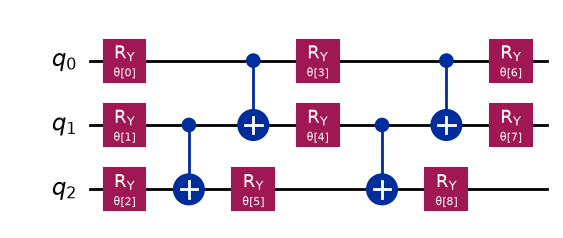

In [16]:
ansatz = real_amplitudes(3, reps=2)        # RY layers + CX entanglers: 3 * (reps + 1) = 9 angles
fmap = zz_feature_map(2, reps=1)
print("real_amplitudes(3, reps=2):", ansatz.num_parameters, "parameters", [prm.name for prm in ansatz.parameters][:4], "...")
print("zz_feature_map(2, reps=1)  :", [prm.name for prm in fmap.parameters])
ansatz.draw("mpl", fold=-1)

Transpile the parameterized circuit once and bind afterwards: `generate_preset_pass_manager(...).run(ansatz)` keeps the parameters symbolic, so a parameter sweep does not pay the transpilation cost again for every value.

### Practice 3.3 — A small ansatz with a ParameterVector

Build `ex3_qc` on 3 qubits using a `ParameterVector` named `"θ"` with 3 elements (store it in `ex3_theta`):

1. `ry(θ[i])` on qubit i for i = 0, 1, 2;
2. `cx(0, 1)` then `cx(1, 2)`;
3. a final `rz(θ[0] + θ[2])` on qubit 2 (re-using two parameters in one expression).

Then create `ex3_bound` by binding θ = [π, 0, π/2] with a single dictionary entry keyed by the vector.

In [ ]:
ex3_theta = None   # TODO: ParameterVector named "θ" with 3 elements
ex3_qc = None      # TODO: build the circuit
ex3_bound = None   # TODO: ex3_qc.assign_parameters({ex3_theta: [...]})

In [ ]:
# Run this cell to check your answer
assert ex3_qc is not None and ex3_bound is not None, "complete ex3_qc and ex3_bound first"
assert [p.name for p in ex3_qc.parameters] == ["θ[0]", "θ[1]", "θ[2]"], ex3_qc.parameters
assert dict(ex3_qc.count_ops()) == {"ry": 3, "cx": 2, "rz": 1}, ex3_qc.count_ops()
assert ex3_bound.num_parameters == 0
ex3_ref = QuantumCircuit(3)
for i, val in enumerate([np.pi, 0, np.pi / 2]):
    ex3_ref.ry(val, i)
ex3_ref.cx(0, 1); ex3_ref.cx(1, 2); ex3_ref.rz(np.pi + np.pi / 2, 2)
assert Statevector(ex3_bound).equiv(Statevector(ex3_ref)), "gates or binding differ from the specification"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex3_theta = ParameterVector("θ", 3)
ex3_qc = QuantumCircuit(3)
for i in range(3):
    ex3_qc.ry(ex3_theta[i], i)
ex3_qc.cx(0, 1)
ex3_qc.cx(1, 2)
ex3_qc.rz(ex3_theta[0] + ex3_theta[2], 2)
ex3_bound = ex3_qc.assign_parameters({ex3_theta: [np.pi, 0, np.pi / 2]})
```

`ex3_theta[i]` is a `ParameterVectorElement`, so it can be used like any `Parameter` and combined into the expression `ex3_theta[0] + ex3_theta[2]`. The circuit still has only 3 free parameters, because it counts the underlying atoms. A dictionary key that is a `ParameterVector` binds the whole vector from a list in index order.

</details>

### Practice 3.4 — Bind by position — mind the order

`ex4_qc` below uses parameters named `"gamma"`, `"beta"` and a `ParameterVector` `"w"` of length 2.

1. Write `ex4_values`, a plain list of 4 numbers such that `ex4_qc.assign_parameters(ex4_values)` sets beta = 0.1, gamma = 0.2, w[0] = 0.3, w[1] = 0.4.
2. Create `ex4_partial`: a new circuit in which only gamma is bound (to 0.2) and the other parameters stay free.

In [ ]:
ex4_gamma, ex4_beta = Parameter("gamma"), Parameter("beta")
ex4_w = ParameterVector("w", 2)
ex4_qc = QuantumCircuit(2)
ex4_qc.rx(ex4_gamma, 0)
ex4_qc.ry(ex4_w[1], 1)
ex4_qc.cx(0, 1)
ex4_qc.rz(ex4_beta, 1)
ex4_qc.ry(ex4_w[0], 0)

ex4_values = None    # TODO: list of 4 numbers in the order of ex4_qc.parameters
ex4_partial = None   # TODO: bind only gamma = 0.2 (new circuit)

In [ ]:
# Run this cell to check your answer
assert ex4_values is not None and ex4_partial is not None, "complete ex4_values and ex4_partial first"
ex4_expected = ex4_qc.assign_parameters({ex4_beta: 0.1, ex4_gamma: 0.2, ex4_w[0]: 0.3, ex4_w[1]: 0.4})
assert Operator(ex4_qc.assign_parameters(ex4_values)) == Operator(ex4_expected), \
    "the list order does not match ex4_qc.parameters"
assert [p.name for p in ex4_partial.parameters] == ["beta", "w[0]", "w[1]"], ex4_partial.parameters
assert ex4_qc.num_parameters == 4, "ex4_qc itself must stay unbound"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex4_gamma, ex4_beta = Parameter("gamma"), Parameter("beta")
ex4_w = ParameterVector("w", 2)
ex4_qc = QuantumCircuit(2)
ex4_qc.rx(ex4_gamma, 0)
ex4_qc.ry(ex4_w[1], 1)
ex4_qc.cx(0, 1)
ex4_qc.rz(ex4_beta, 1)
ex4_qc.ry(ex4_w[0], 0)

ex4_values = [0.1, 0.2, 0.3, 0.4]       # order: beta, gamma, w[0], w[1]
ex4_partial = ex4_qc.assign_parameters({ex4_gamma: 0.2})
```

`ex4_qc.parameters` is `[beta, gamma, w[0], w[1]]`: plain names sort alphabetically (`b` < `g` < `w`) and the vector elements follow in index order. The insertion order (`gamma, w[1], beta, w[0]`) is irrelevant. Partial binding needs a dictionary; a list must cover every parameter.

</details>

Q3.4. Which two statements about `QuantumCircuit.assign_parameters` in Qiskit 2.x are true? (Select two.)

A. By default it returns a new circuit and leaves the original circuit unchanged.

B. With `inplace=True` it returns the modified circuit, so `qc = qc.assign_parameters(v, inplace=True)` is safe.

C. A list of values is matched to the parameters in the order in which the gates were added.

D. Binding a `Parameter` that does not appear in the circuit raises `CircuitError` unless `strict=False` is passed.

E. Partial binding is done by passing a list with `None` for the parameters that should stay free.

<details>
<summary>Show answer</summary>

Answer: A, D

A: the default is `inplace=False`, which returns a bound copy. D: `strict=True` is the default and rejects unknown keys. B is the classic trap — the in-place call returns `None`. C: lists follow the sorted `qc.parameters` order. E: `None` is not a valid value (it raises `TypeError`); partial binding uses a dictionary.

</details>

<a id="s3-core-59"></a>

## 3.1 Construct dynamic circuits

A dynamic circuit measures qubits in the middle of a shot and uses the results during the same shot to decide what happens next (classical feedforward and control flow). Typical uses: active qubit reset, teleportation, error-correction syndrome handling, repeat-until-success, and constant-depth long-range entanglement.

Qiskit 2.0 removed `Instruction.c_if()` and the `condition` attribute of ordinary gates. Conditional logic is written with the control-flow builders, all used as context managers:

| Builder | Operation name (in `count_ops()` and in a backend `Target`) | Class |
|---|---|---|
| `with qc.if_test(cond) as else_:` … `with else_:` | `if_else` | `IfElseOp` |
| `with qc.switch(target) as case:` … `with case(0):` | `switch_case` | `SwitchCaseOp` |
| `with qc.for_loop(range(n)) as i:` | `for_loop` | `ForLoopOp` |
| `with qc.while_loop(cond):` | `while_loop` | `WhileLoopOp` |
| `qc.break_loop()`, `qc.continue_loop()` inside loops | `break_loop`, `continue_loop` | `BreakLoopOp`, `ContinueLoopOp` |
| `with qc.box():` (new in Qiskit 2.0) | `box` | `BoxOp` |

A condition is a tuple `(clbit, 0 or 1)`, a tuple `(ClassicalRegister, integer)`, or a Boolean expression built with `qiskit.circuit.classical.expr`.

In [17]:
legacy = QuantumCircuit(1, 1)
try:
    legacy.x(0).c_if(legacy.clbits[0], 1)       # Qiskit 0.x / 1.x style
except AttributeError as err:
    print("AttributeError:", err)

AttributeError: 'InstructionSet' object has no attribute 'c_if'


### Mid-circuit measurement, reset and `if_test`

Active reset: measure a qubit, and flip it back to $|0\rangle$ only if the result was 1.

{'00': 507, '01': 493}


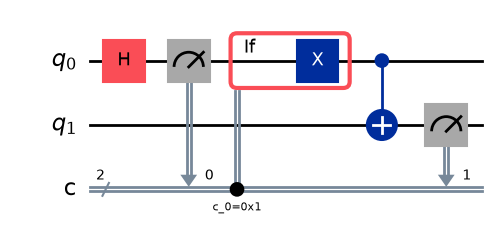

In [18]:
qr = QuantumRegister(2, "q")
c = ClassicalRegister(2, "c")
dyn = QuantumCircuit(qr, c)
dyn.h(0)
dyn.measure(0, c[0])             # mid-circuit measurement
with dyn.if_test((c[0], 1)):     # feedforward: executed only when c[0] == 1
    dyn.x(0)
dyn.cx(0, 1)                     # qubit 0 is |0> again, so qubit 1 stays |0>
dyn.measure(1, c[1])
print(run_counts(dyn))           # c[1] (left bit) is always 0
dyn.draw("mpl")

In [19]:
# With an else branch: keep the handle returned by if_test and open it as a second context
ie = QuantumCircuit(QuantumRegister(2, "q"), ClassicalRegister(2, "c"))
ie.h(0)
ie.measure(0, 0)
with ie.if_test((ie.clbits[0], 1)) as else_:
    ie.x(1)                      # c[0] == 1  -> X   -> c[1] = 1
with else_:
    ie.h(1)                      # c[0] == 0  -> H   -> c[1] random
ie.measure(1, 1)
print(ie.draw(fold=-1))
print(run_counts(ie, shots=2000))

     ┌───┐┌─┐                                            
q_0: ┤ H ├┤M├────────────────────────────────────────────
     └───┘└╥┘  ┌──────  ┌───┐┌──────── ┌───┐ ───────┐ ┌─┐
q_1: ──────╫───┤ If-0  ─┤ X ├┤ Else-0  ┤ H ├  End-0 ├─┤M├
           ║   └──╥───  └───┘└──────── └───┘ ───────┘ └╥┘
           ║ ┌────╨────┐                               ║ 
c: 2/══════╩═╡ c_0=0x1 ╞═══════════════════════════════╩═
           0 └─────────┘                               1 


{'10': 492, '11': 1007, '00': 501}


Register conditions compare the whole register with an integer, using the same little-endian convention as counts: `(cr, 2)` means `cr[1] = 1` and `cr[0] = 0`.

In [20]:
qreg = QuantumRegister(3, "q"); creg = ClassicalRegister(2, "c"); flag = ClassicalRegister(1, "flag")
rc = QuantumCircuit(qreg, creg, flag)
rc.h([0, 1])
rc.measure([0, 1], creg)
with rc.if_test((creg, 2)):      # true only for c = 0b10
    rc.x(2)
rc.measure(2, flag)
print(run_counts(rc))            # joined key = flag + c: flag (leftmost bit) is 1 only for c = 10

{'110': 242, '001': 240, '011': 253, '000': 265}


The Python method is called `if_test`, but the operation it creates is named `if_else` — that is the name you look for in `qc.count_ops()` and in `backend.target.operation_names`.

`AerSimulator` executes mid-circuit measurements and every control-flow operation, so `SamplerV2(mode=AerSimulator())` (the `run_counts` helper) runs all dynamic circuits of this part locally. `Statevector` cannot: it has no notion of measurement results during a shot.

Q3.5. The circuit in the figure is run with many shots on an ideal simulator. What is the probability of observing the bitstring `10`?

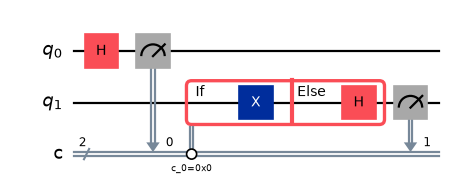

A. 0 %

B. 25 %

C. 50 %

D. 75 %

<details>
<summary>Show answer</summary>

Answer: C

The condition is `c[0] == 0`. With probability 1/2 the first measurement gives 0; then X is applied to qubit 1 and `c[1] = 1`, which is the string `10` (c[1] on the left, c[0] on the right). With probability 1/2 it gives 1; the else branch applies H, giving `01` or `11` with 1/4 each. So P(`10`) = 1/2. The tempting 25 % is P(`01`), i.e. the result when the bitstring is read in the wrong order.

</details>

### Classical expressions: `qiskit.circuit.classical.expr`

> **Study priority.** First-pass focus: understand what a classical expression tests and how it controls a block. Building the three-bit parity expression in Practice 3.6 is an optional extension.

Richer conditions are built from `Clbit`s, `ClassicalRegister`s and integers with functions from `expr`:

| Kind | Functions | Result type |
|---|---|---|
| logical | `logic_and`, `logic_or`, `logic_not` | `Bool` |
| bitwise | `bit_and`, `bit_or`, `bit_xor`, `bit_not` | same width as the operands (a single bit is `Bool`) |
| comparison | `equal`, `not_equal`, `less`, `less_equal`, `greater`, `greater_equal` | `Bool` |
| other | `lift`, `cast`, `index`, `shift_left`, `shift_right`; arithmetic `add`, `sub`, `mul`, `div` | – |

Python operators do not build conditions: `c[0] ^ c[1]` or `c[0] & c[1]` raise `TypeError`, and a Python `if c[0]:` is evaluated once, when the circuit is built, not at run time.

In [21]:
qreg = QuantumRegister(3, "q"); creg = ClassicalRegister(2, "c"); flag = ClassicalRegister(1, "f")
ex_c = QuantumCircuit(qreg, creg, flag)
ex_c.h([0, 1])
ex_c.measure([0, 1], creg)
cond = expr.logic_or(expr.equal(creg, 3), expr.logic_not(creg[0]))   # c == 3  or  c[0] == 0
print("condition type:", cond.type)
with ex_c.if_test(cond):
    ex_c.x(2)
ex_c.measure(2, flag)
print(run_counts(ex_c))           # joined key = f + c: f (leftmost bit) is 0 only for c = 01

condition type: Bool()
{'110': 242, '001': 240, '111': 253, '100': 265}


Q3.6. The figure shows the circuit to build. The lines before the conditional (`qc.h([0, 1])`, `qc.measure([0, 1], c)`) and after it (`qc.measure(2, f)`) are already written, and `c` is the 2-bit register. Which snippet completes the circuit correctly in Qiskit 2.x?

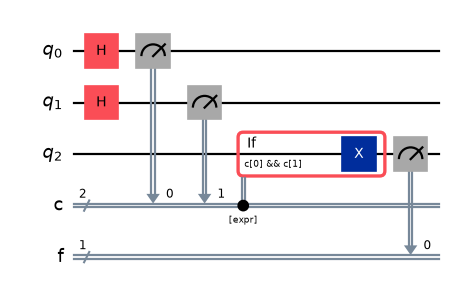

A.

```python
with qc.if_test(c[0] & c[1]):
    qc.x(2)
```

B.

```python
if c[0] and c[1]:
    qc.x(2)
```

C.

```python
qc.x(2).c_if(c, 3)
```

D.

```python
with qc.if_test(expr.logic_and(c[0], c[1])):
    qc.x(2)
```

<details>
<summary>Show answer</summary>

Answer: D

Run-time conditions must be `expr` expressions (or `(bit, value)` / `(register, value)` tuples). A raises `TypeError`: `Clbit` does not support `&`. B is plain Python evaluated while the circuit is built: a `Clbit` object is truthy, so an unconditional X is appended. C uses `c_if`, which was removed in Qiskit 2.0 (`AttributeError`).

</details>

### `switch`, loops and `box`

`switch` jumps on the value of a register (or bit, or integer-typed expression). A case may list several values, and `case.DEFAULT` catches everything else.

In [22]:
qreg = QuantumRegister(3, "q"); creg = ClassicalRegister(2, "c"); o = ClassicalRegister(1, "o")
sw = QuantumCircuit(qreg, creg, o)
sw.h([0, 1])
sw.measure([0, 1], creg)
with sw.switch(creg) as case:
    with case(0):
        pass                      # c = 0: do nothing
    with case(1, 2):
        sw.x(2)                   # c = 1 or 2: flip
    with case(case.DEFAULT):
        sw.h(2)                   # anything else (c = 3): superpose
sw.measure(2, o)
print(dict(sw.count_ops()))
print(run_counts(sw, shots=2000))

{'measure': 3, 'h': 2, 'switch_case': 1}
{'110': 492, '101': 508, '011': 241, '000': 501, '111': 258}


In [23]:
# for_loop: the body is repeated; the loop variable is a Parameter you may use in gates
fl = QuantumCircuit(1, 1)
with fl.for_loop(range(3)) as i:
    fl.x(0)                       # three X gates in total -> |1>
fl.measure(0, 0)
print("for_loop  :", run_counts(fl, shots=100))

# while_loop: repeat until success (measure again while the result is 1)
wl = QuantumCircuit(1, 1)
wl.h(0)
wl.measure(0, 0)
with wl.while_loop((wl.clbits[0], 1)):
    wl.h(0)
    wl.measure(0, 0)
print("while_loop:", run_counts(wl, shots=100))

# box: groups operations into one block (a unit for scheduling / annotations); no condition
bx = QuantumCircuit(2)
with bx.box():
    bx.h(0)
    bx.cx(0, 1)
print("box       :", bx.data[0].operation.name, type(bx.data[0].operation).__name__)

for_loop  : {'1': 100}
while_loop: {'0': 100}
box       : box BoxOp


### Does the backend support it?

A backend advertises control flow in its `Target` by operation name. Transpiling a dynamic circuit for a target that lacks the needed operation fails with `TranspilerError`. Test backends: `GenericBackendV2(num_qubits, control_flow=True)` and fake backends whose snapshot includes `if_else`.

In [24]:
for fake in (FakeManilaV2(), FakeLimaV2(), FakeTorino()):
    ops = fake.target.operation_names
    print(f"{fake.name:14s}", {k: (k in ops) for k in ["if_else", "switch_case", "for_loop", "while_loop"]})

try:
    generate_preset_pass_manager(optimization_level=1, backend=FakeLimaV2()).run(dyn)
except Exception as err:
    print(type(err).__name__, "->", err)

fake_manila    {'if_else': True, 'switch_case': True, 'for_loop': True, 'while_loop': False}


fake_lima      {'if_else': False, 'switch_case': False, 'for_loop': False, 'while_loop': False}


fake_torino    {'if_else': True, 'switch_case': True, 'for_loop': True, 'while_loop': False}


TranspilerError -> "The control-flow construct 'if_else' is not supported by the backend."


With an IBM Quantum account you can also filter the live backends (shown, not executed here):

```python
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService(channel="ibm_quantum_platform", token="<API key>", instance="<instance CRN>")
print(service.backends(dynamic_circuits=True))
print("if_else" in service.backend("ibm_fez").target.operation_names)
```

Hardware restrictions, per the IBM documentation (guide Execute dynamic circuits). Qiskit and Aer accept more than the hardware does:

- an `if_test` operand may have at most 32 bits (a one-bit condition on a large register is fine);
- nested conditionals are not supported, and measurements or resets inside a conditional body are not supported;
- arithmetic in classical expressions is not supported (logical, bitwise and comparison operations are);
- the `for`, `while` and `switch` instructions are not supported on the hardware. The fake-backend snapshots above (`FakeManilaV2`, `FakeTorino`) still list `for_loop` and `switch_case` in their targets, so Qiskit will transpile such circuits for them; for current hardware the restriction list in the IBM documentation is authoritative;
- control electronics limit the number of classical broadcasts per job (about 300 broadcasts of 60 bits, or 2400 single-bit broadcasts);
- `EstimatorV2` does not accept dynamic circuits — use `SamplerV2` and compute expectation values yourself.

On the exam, "which is not a limitation" questions usually hinge on the difference between logical / bitwise operations (supported) and arithmetic (not supported), or on the fact that a large register is fine as long as the compared operand is at most 32 bits.

### Practice 3.5 — Teleportation with feedforward

Complete `ex5_qc` so that it teleports the state of qubit 0 (prepared by `ry(1.1)`) to qubit 2:

1. make a Bell pair on qubits 1 and 2 (H on 1, CX 1→2);
2. Bell-basis measurement: CX 0→1, H on 0, measure qubit 0 into `m[0]` and qubit 1 into `m[1]`;
3. corrections with `if_test`: X on qubit 2 if `m[1] == 1`, then Z on qubit 2 if `m[0] == 1`;
4. measure qubit 2 into `out[0]`.

The check verifies that P(out = 1) matches $\sin^2(\theta/2)$ for $\theta = 1.1$.

In [ ]:
ex5_theta = 1.1
ex5_q = QuantumRegister(3, "q")
ex5_m = ClassicalRegister(2, "m")
ex5_out = ClassicalRegister(1, "out")
ex5_qc = QuantumCircuit(ex5_q, ex5_m, ex5_out)
ex5_qc.ry(ex5_theta, 0)          # state to teleport
# TODO 1: Bell pair on qubits 1, 2
# TODO 2: Bell-basis measurement of qubits 0, 1 into m[0], m[1]
# TODO 3: feedforward corrections on qubit 2 with if_test
# TODO 4: measure qubit 2 into out[0]

In [ ]:
# Run this cell to check your answer
assert ex5_qc.count_ops().get("if_else", 0) >= 2, "use if_test for both the X and the Z correction"
ex5_counts = run_counts(ex5_qc, shots=4000)
ex5_p1 = sum(n for key, n in ex5_counts.items() if key[0] == "1") / 4000   # joined key = out + m
print(f"P(out=1) = {ex5_p1:.3f}   expected sin^2(theta/2) = {np.sin(ex5_theta / 2) ** 2:.3f}")
assert abs(ex5_p1 - np.sin(ex5_theta / 2) ** 2) < 0.03, "the teleported state is wrong"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex5_theta = 1.1
ex5_q = QuantumRegister(3, "q")
ex5_m = ClassicalRegister(2, "m")
ex5_out = ClassicalRegister(1, "out")
ex5_qc = QuantumCircuit(ex5_q, ex5_m, ex5_out)
ex5_qc.ry(ex5_theta, 0)
ex5_qc.h(1)
ex5_qc.cx(1, 2)
ex5_qc.cx(0, 1)
ex5_qc.h(0)
ex5_qc.measure(0, ex5_m[0])
ex5_qc.measure(1, ex5_m[1])
with ex5_qc.if_test((ex5_m[1], 1)):
    ex5_qc.x(2)
with ex5_qc.if_test((ex5_m[0], 1)):
    ex5_qc.z(2)
ex5_qc.measure(2, ex5_out[0])
```

After the Bell measurement, qubit 2 holds $X^{m_1} Z^{m_0}|\psi\rangle$, so applying X when `m[1] = 1` and Z when `m[0] = 1` restores $|\psi\rangle$. Without the corrections qubit 2 would give 1 with probability 1/2. The Z correction does not change Z-basis statistics, so the check also counts the `if_else` operations; a basis change before the final measurement would reveal a missing Z. Each `if_test` has a one-bit operand and no nesting, so this circuit is within the hardware restrictions.

</details>

### Practice 3.6 — A parity flag with an `expr` condition

> **Optional extension.** Practice 3.6: build a compound classical expression. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s3-resume-83). Later core code does not require this block.

Build `ex6_qc` from `QuantumRegister(4, "q")`, `ClassicalRegister(3, "c")` and `ClassicalRegister(1, "flag")`:

1. H on qubits 0, 1, 2 and measure them into `c`;
2. use one `if_test` whose condition is an `expr` expression that is true when the parity $c_0 \oplus c_1 \oplus c_2$ is odd, and apply X to qubit 3 inside it;
3. measure qubit 3 into `flag`.

In [ ]:
ex6_q = QuantumRegister(4, "q")
ex6_c = ClassicalRegister(3, "c")
ex6_flag = ClassicalRegister(1, "flag")
ex6_qc = QuantumCircuit(ex6_q, ex6_c, ex6_flag)
# TODO: H on qubits 0-2, measure into ex6_c
# TODO: if_test with an expr parity condition -> X on qubit 3
# TODO: measure qubit 3 into ex6_flag

In [ ]:
# Run this cell to check your answer
ex6_ifs = [inst.operation for inst in ex6_qc.data if inst.operation.name == "if_else"]
assert len(ex6_ifs) == 1, "use exactly one if_test"
assert isinstance(ex6_ifs[0].condition, expr.Expr), "the condition should be an expr expression"
ex6_counts = run_counts(ex6_qc, shots=2000)
assert len(ex6_counts) == 8, ex6_counts
for key in ex6_counts:
    f_bit, bits = key[0], key[1:]             # joined key = flag + c
    assert int(f_bit) == bits.count("1") % 2, f"wrong flag for {key}"
print(ex6_counts)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex6_q = QuantumRegister(4, "q")
ex6_c = ClassicalRegister(3, "c")
ex6_flag = ClassicalRegister(1, "flag")
ex6_qc = QuantumCircuit(ex6_q, ex6_c, ex6_flag)
ex6_qc.h([0, 1, 2])
ex6_qc.measure([0, 1, 2], ex6_c)
ex6_parity = expr.bit_xor(expr.bit_xor(ex6_c[0], ex6_c[1]), ex6_c[2])
with ex6_qc.if_test(ex6_parity):
    ex6_qc.x(3)
ex6_qc.measure(3, ex6_flag)
```

`expr.bit_xor` of two single bits is a Boolean, so nesting two of them gives the 3-bit parity. Writing `ex6_c[0] ^ ex6_c[1]` would raise `TypeError`. An equivalent condition is `expr.equal(expr.bit_xor(...), True)`. On IBM hardware this is allowed: bitwise XOR is not arithmetic.

</details>

<a id="s3-resume-83"></a>

Q3.7. You built a circuit with `qc.if_test(...)` and want to check, before transpiling, whether `backend` (a `BackendV2`) can run it. Which expression is correct?

A. `"if_test" in backend.target.operation_names`

B. `"if_else" in backend.target.operation_names`

C. `backend.target.supports_dynamic_circuits`

D. `"c_if" in backend.target.operation_names`

<details>
<summary>Show answer</summary>

Answer: B

`if_test` is only the builder method; the operation it appends is `IfElseOp`, whose name is `if_else`, and that is the name listed in the target. A is always `False`. C does not exist (`AttributeError`). `c_if` was a method on instructions and was removed in Qiskit 2.0; it never appears in a target.

</details>

<a id="s3-core-88"></a>

## 3.3 Transpile and optimize circuits

### Why transpile: ISA circuits

A backend is described by a `Target`: which operations exist (basis gates plus `measure`, `reset`, `delay`, control flow …), on which physical qubits or directed qubit pairs they act (the coupling map), and their error rates and durations. An ISA circuit (instruction set architecture circuit) uses only those operations, on physical qubits, and applies two-qubit gates only to connected pairs. Since March 2024, IBM Quantum Runtime primitives accept only ISA circuits, so transpiling is a mandatory step.

In [25]:
backend = FakeManilaV2()
print(backend.name, "|", backend.num_qubits, "qubits")
print("operations  :", sorted(backend.target.operation_names))
print("coupling map:", backend.coupling_map.get_edges())      # directed pairs of a 5-qubit line

fake_manila | 5 qubits
operations  : ['cx', 'delay', 'for_loop', 'id', 'if_else', 'measure', 'reset', 'rz', 'switch_case', 'sx', 'x']
coupling map: EdgeList[(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 4), (4, 3)]


In [26]:
from qiskit_ibm_runtime import SamplerV2

abstract = QuantumCircuit(2)
abstract.h(0)
abstract.cx(0, 1)
abstract.measure_all()
try:
    SamplerV2(mode=backend).run([abstract])          # local testing mode with a fake backend
except Exception as err:
    print(type(err).__name__, "->", str(err)[:110], "...")
# (on AerSimulator.from_backend(backend) the same circuit fails later, inside Aer, with AerError)

IBMInputValueError -> 'The instruction h on qubits (0,) is not supported by the target system. Circuits that do not match the target ...


### `generate_preset_pass_manager`

```python
generate_preset_pass_manager(optimization_level=2, backend=None, target=None,
                             basis_gates=None, coupling_map=None, initial_layout=None,
                             layout_method=None, routing_method=None, translation_method=None,
                             scheduling_method=None, seed_transpiler=None, ...)
```

- Returns a `StagedPassManager`; call `.run(circuit)` or `.run([circuits])`.
- The default `optimization_level` is 2.
- Constraints: `target` wins over `backend`; loose constraints (`basis_gates`, `coupling_map`, `dt`) given together with a `backend` override the backend's values. Without a backend, target or loose constraints there is nothing to map onto: no layout, routing or translation happens.
- `transpile(circuits, backend, optimization_level=..., seed_transpiler=...)` builds the same preset pass manager internally (also default level 2).

In [27]:
pm = generate_preset_pass_manager(optimization_level=2, backend=backend, seed_transpiler=7)
isa = pm.run(abstract)
print(type(pm).__name__)
print(isa.draw(idle_wires=False, fold=-1))
print("ops:", dict(isa.count_ops()), "| num_qubits:", isa.num_qubits)
print("identical to transpile():", isa == transpile(abstract, backend=backend, seed_transpiler=7))
print("stages:", pm.stages)

device_sim = AerSimulator.from_backend(backend)      # noisy simulator with Manila's target and noise model
dev_sampler = SamplerV2(mode=device_sim)
dev_sampler.options.simulator.seed_simulator = 7
print("ISA circuit on the device model:", dev_sampler.run([isa], shots=1000).result()[0].data.meas.get_counts())

StagedPassManager
global phase: π/4
         ┌─────────┐┌────┐┌─────────┐      ░ ┌─┐   
q_0 -> 3 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├──■───░─┤M├───
         └─────────┘└────┘└─────────┘┌─┴─┐ ░ └╥┘┌─┐
q_1 -> 4 ────────────────────────────┤ X ├─░──╫─┤M├
                                     └───┘ ░  ║ └╥┘
 meas: 2/═════════════════════════════════════╩══╩═
                                              0  1 
ops: {'rz': 2, 'measure': 2, 'sx': 1, 'cx': 1, 'barrier': 1} | num_qubits: 5
identical to transpile(): True
stages: ('init', 'layout', 'routing', 'translation', 'optimization', 'scheduling')


ISA circuit on the device model: {'00': 506, '11': 462, '01': 19, '10': 13}


The transpiled circuit has as many qubits as the device (5 here, 127 or 156 on large backends). The unused physical qubits are added as idle ancillas — draw with `idle_wires=False` to hide them.

### The six stages

> **Study priority.** Keep the purpose and order of the stages on the core path. The later custom-pass example shows how to modify the pipeline and can be revisited after using preset pass managers confidently.

| Stage | Job | Typical passes |
|---|---|---|
| `init` | unroll custom instructions and gates on 3+ qubits into 1- and 2-qubit gates; early logical simplifications (levels 1–3) | `HighLevelSynthesis`, `UnitarySynthesis` / `Unroll3qOrMore` (3+ qubits), `InverseCancellation` |
| `layout` | choose a physical qubit for every virtual qubit | `SetLayout` (your `initial_layout`), `TrivialLayout`, `VF2Layout`, `SabreLayout`, `DenseLayout` |
| `routing` | insert SWAPs so every 2-qubit gate acts on a connected pair | `SabreSwap` (default), `BasicSwap`, `LookaheadSwap` |
| `translation` | rewrite every gate into the target's basis gates | `BasisTranslator` (default), `UnitarySynthesis` |
| `optimization` | repeat simplifications until the circuit stops improving; re-translate if needed | `Optimize1qGatesDecomposition`, `InverseCancellation`, `CommutativeCancellation`, 2-qubit block resynthesis |
| `scheduling` | only when `scheduling_method` is set: compute timing and insert explicit `delay`s on idle qubits | `ALAPScheduleAnalysis` / `ASAPScheduleAnalysis`, `PadDelay`, `PadDynamicalDecoupling` |

Every stage also has `pre_` and `post_` hooks (`pre_layout`, `post_optimization`, …; listed by `pm.expanded_stages`) where you can plug in your own passes.

Q3.8. In which order does a preset `StagedPassManager` run its main stages?

A. layout → init → translation → routing → optimization → scheduling

B. init → translation → layout → routing → scheduling → optimization

C. init → layout → translation → routing → optimization → scheduling

D. init → layout → routing → translation → optimization → scheduling

<details>
<summary>Show answer</summary>

Answer: D

`pm.stages` is `('init', 'layout', 'routing', 'translation', 'optimization', 'scheduling')`. Routing comes right after layout (both deal with physical qubits), and translation follows routing so that the inserted SWAPs are also translated into basis gates. Scheduling is always last because timing is only meaningful for the final gate sequence.

</details>

### Optimization levels 0–3

| Level | Meaning | Layout (when no `initial_layout` is given) | Optimization |
|---|---|---|---|
| 0 | no optimization (hardware characterization, "run exactly these gates") | `TrivialLayout` (virtual i → physical i) | none; basic translation only |
| 1 | light | `TrivialLayout` if it needs no SWAPs, else `VF2Layout` (perfect-match search), else `SabreLayout` | 1-qubit gate merging (`Optimize1qGatesDecomposition`) and `InverseCancellation` (e.g. CX·CX, H·H) |
| 2 (default) | medium | `VF2Layout`, else `SabreLayout` with more trials | level 1 plus `CommutativeCancellation`, removal of identity-equivalent gates and of diagonal gates before measurement; 2-qubit blocks are consolidated and resynthesized once before the optimization loop |
| 3 | heavy | same as 2 with larger search budgets | as level 2, but the 2-qubit block resynthesis (`ConsolidateBlocks` + `UnitarySynthesis`) runs inside the optimization loop, which keeps the best depth/size found |

All levels still do layout, routing and translation when a target is given, so level 0 also produces an ISA circuit. At levels 1–3 the routing stage ends with `VF2PostLayout`, which may move the routed circuit to lower-error physical qubits. The default routing method is Sabre at every level (at levels 1–3 `SabreLayout` already routes while it searches for a layout). Higher levels cost more compile time and do not always give a better circuit.

level 0: depth= 135   CZ count= 33   size= 181


level 1: depth=  76   CZ count= 27   size= 136
level 2: depth=  63   CZ count= 18   size=  86
level 3: depth=  63   CZ count= 18   size=  86


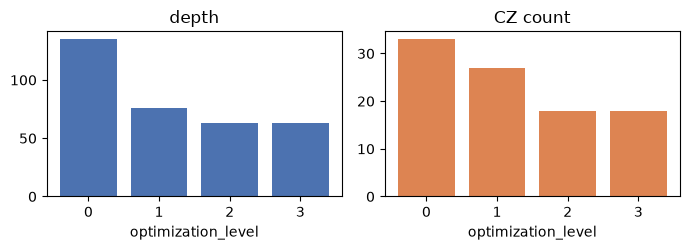

In [28]:
qft = QuantumCircuit(4)
qft.append(QFTGate(4), range(4))
qft.measure_all()

torino = FakeTorino()          # 133-qubit Heron snapshot, CZ basis
rows = []
for level in range(4):
    pm_lvl = generate_preset_pass_manager(optimization_level=level, backend=torino, seed_transpiler=42)
    t = pm_lvl.run(qft)
    rows.append((level, t.depth(), t.count_ops().get("cz", 0), t.size()))
    print(f"level {level}: depth={rows[-1][1]:4d}   CZ count={rows[-1][2]:3d}   size={rows[-1][3]:4d}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2.6))
ax1.bar([r[0] for r in rows], [r[1] for r in rows], color="#4c72b0"); ax1.set_title("depth")
ax2.bar([r[0] for r in rows], [r[2] for r in rows], color="#dd8452"); ax2.set_title("CZ count")
for ax in (ax1, ax2):
    ax.set_xlabel("optimization_level"); ax.set_xticks(range(4))
fig.tight_layout()
plt.show()

In [29]:
# Redundant pairs survive level 0 but not level 1 - unless a barrier separates them
pair = QuantumCircuit(2)
pair.h(0); pair.h(0); pair.cx(0, 1); pair.cx(0, 1)
fenced = QuantumCircuit(2)
fenced.h(0); fenced.barrier(); fenced.h(0)

for level in (0, 1):
    pm_l = generate_preset_pass_manager(optimization_level=level, basis_gates=["rz", "sx", "x", "cx"])
    print(f"level {level}:  pair -> {dict(pm_l.run(pair).count_ops())}   fenced -> {dict(pm_l.run(fenced).count_ops())}")

level 0:  pair -> {'rz': 4, 'sx': 2, 'cx': 2}   fenced -> {'rz': 4, 'sx': 2, 'barrier': 1}
level 1:  pair -> {}   fenced -> {'rz': 4, 'sx': 2, 'barrier': 1}


Level 0 = "no optimization", not "no transpilation". The default of both `generate_preset_pass_manager` and `transpile` is level 2. Barriers block optimization across them.

### Stochastic passes and `seed_transpiler`

`SabreLayout` and `SabreSwap` use randomized trials, so the same call can return different circuits. Fix `seed_transpiler` to make results reproducible (important for tests, benchmarks and exam-style "what is printed" questions).

In [30]:
rng = np.random.default_rng(7)
rand_cx = QuantumCircuit(8)
for _ in range(20):
    i, j = rng.choice(8, 2, replace=False)
    rand_cx.cx(int(i), int(j))

def cz_and_depth(seed):
    t = generate_preset_pass_manager(optimization_level=1, backend=torino, seed_transpiler=seed).run(rand_cx)
    return t.count_ops().get("cz", 0), t.depth()

print("seeds 0-5      :", [cz_and_depth(s) for s in range(6)])
print("seed 5, 3 times:", [cz_and_depth(5) for _ in range(3)])

seeds 0-5      : [(50, 87), (62, 99), (53, 90), (53, 89), (56, 103), (50, 81)]
seed 5, 3 times: [(50, 81), (50, 81), (50, 81)]


### Layout and routing in practice

- `initial_layout=[p0, p1, ...]` puts virtual qubit i on physical qubit `p_i` (skips layout selection).
- `layout_method`: `"trivial"`, `"dense"`, `"sabre"` (or `"default"`); `routing_method`: `"sabre"`, `"basic"`, `"lookahead"`, `"none"` (`"none"` raises if routing would be needed).
- The result carries a `TranspileLayout` in `isa.layout` (`None` for circuits that were never transpiled):

| Method | Meaning |
|---|---|
| `initial_index_layout(filter_ancillas=True)` | physical qubit where each virtual qubit starts |
| `final_index_layout()` | physical qubit where each virtual qubit's state ends (after routing SWAPs) |
| `routing_permutation()` | permutation of physical qubits caused by routing |

Loose constraints make a tiny example: a 3-qubit line `0–1–2` and a circuit that needs a CX between qubits 0 and 2.

In [31]:
tri = QuantumCircuit(3)
tri.h(0); tri.cx(0, 1); tri.cx(1, 2); tri.cx(0, 2)
tri.measure_all()

line_pm = generate_preset_pass_manager(
    optimization_level=1,
    basis_gates=["rz", "sx", "x", "cx"],
    coupling_map=CouplingMap([[0, 1], [1, 0], [1, 2], [2, 1]]),
    initial_layout=[0, 1, 2],
    seed_transpiler=3,
)
routed = line_pm.run(tri)
print(routed.draw(fold=-1))
print("initial:", routed.layout.initial_index_layout(filter_ancillas=True),
      "| final:", routed.layout.final_index_layout(),
      "| routing permutation:", routed.layout.routing_permutation())
print("layout of the untranspiled circuit:", tri.layout)

global phase: π/4
         ┌─────────┐┌────┐┌─────────┐                               ░ ┌─┐      
q_0 -> 0 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├──■────────────────────────■───░─┤M├──────
         └─────────┘└────┘└─────────┘┌─┴─┐     ┌───┐     ┌───┐┌─┴─┐ ░ └╥┘   ┌─┐
q_1 -> 1 ────────────────────────────┤ X ├──■──┤ X ├──■──┤ X ├┤ X ├─░──╫────┤M├
                                     └───┘┌─┴─┐└─┬─┘┌─┴─┐└─┬─┘└───┘ ░  ║ ┌─┐└╥┘
q_2 -> 2 ─────────────────────────────────┤ X ├──■──┤ X ├──■────────░──╫─┤M├─╫─
                                          └───┘     └───┘           ░  ║ └╥┘ ║ 
 meas: 3/══════════════════════════════════════════════════════════════╩══╩══╩═
                                                                       0  1  2 
initial: [0, 1, 2] | final: [0, 2, 1] | routing permutation: [0, 2, 1]
layout of the untranspiled circuit: None


The router moved virtual qubits 1 and 2 (final layout `[0, 2, 1]`) and the final measurements follow them, so the counts are still reported for the original qubits. When you post-process results of a transpiled circuit without final measurements (e.g. observables), use `final_index_layout()` or pass the layout to `SparsePauliOp.apply_layout` (Section 6).

### Translation and scheduling

In [32]:
basis_pm = generate_preset_pass_manager(optimization_level=1, basis_gates=["rz", "sx", "x", "cx"])
swap = QuantumCircuit(2); swap.swap(0, 1)
toff = QuantumCircuit(3); toff.ccx(0, 1, 2)
print("SWAP    ->", dict(basis_pm.run(swap).count_ops()))
print("Toffoli ->", dict(basis_pm.run(toff).count_ops()))

ghz3 = QuantumCircuit(3); ghz3.h(0); ghz3.cx(0, 1); ghz3.cx(1, 2); ghz3.measure_all()
for method in (None, "alap"):
    t = generate_preset_pass_manager(optimization_level=1, backend=backend, scheduling_method=method,
                                     seed_transpiler=1).run(ghz3)
    print(f"scheduling_method={method!s:5s} -> delay instructions: {t.count_ops().get('delay', 0)}")

SWAP    -> {'cx': 3}
Toffoli -> {'rz': 10, 'cx': 6, 'sx': 2}
scheduling_method=None  -> delay instructions: 0
scheduling_method=alap  -> delay instructions: 5


In [33]:
# A small ISA checker (reused by the practice checks below)
def is_isa(circuit, target):
    # every instruction (barriers aside) must be supported by the target on exactly those physical qubits
    for inst in circuit.data:
        if inst.operation.name == "barrier":
            continue
        qargs = tuple(circuit.find_bit(q).index for q in inst.qubits)
        if not target.instruction_supported(inst.operation.name, qargs):
            return False
    return True

print("abstract circuit is ISA  :", is_isa(abstract, backend.target))
print("transpiled circuit is ISA:", is_isa(isa, backend.target))

abstract circuit is ISA  : False
transpiled circuit is ISA: True


### Custom pass managers

> **Optional extension.** Implement a custom pass manager. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s3-resume-107). Later core code does not require this block.

- `PassManager([pass1, pass2, ...])` runs passes in order (`.append(...)` adds more); `.run(circuit)` returns the new circuit.
- `StagedPassManager(stages=[...], init=..., optimization=..., ...)` groups pass managers into named stages.
- A preset pass manager is a `StagedPassManager`, so you can replace a stage (`pm.optimization = ...`) or fill a hook (`pm.pre_layout = ...`). `pm.stages` is a read-only tuple, and `StagedPassManager.append` is not supported.
- In Qiskit 2.0, `InverseCancellation` needs the list of gates (or inverse pairs) to cancel, e.g. `InverseCancellation([HGate(), CXGate(), (TGate(), TdgGate())])`.

In [34]:
messy = QuantumCircuit(2)
messy.h(0); messy.h(0); messy.cx(0, 1); messy.cx(0, 1); messy.rz(0.3, 1); messy.rz(0.4, 1); messy.x(1)

custom = PassManager([
    InverseCancellation([HGate(), CXGate()]),           # remove H.H and CX.CX pairs
    Optimize1qGatesDecomposition(basis=["rz", "sx", "x"]),
])
clean = custom.run(messy)
print(dict(messy.count_ops()), "->", dict(clean.count_ops()))
print("same unitary:", Operator(clean).equiv(Operator(messy)))

staged = StagedPassManager(stages=["init", "optimization"], optimization=custom)
print("custom StagedPassManager stages:", staged.stages)

pm0 = generate_preset_pass_manager(optimization_level=0, backend=backend, seed_transpiler=1)
print("level 0              :", dict(pm0.run(messy).count_ops()))
pm0.pre_layout = PassManager([InverseCancellation([HGate(), CXGate()])])   # plug a pass into a hook
print("level 0 + pre_layout :", dict(pm0.run(messy).count_ops()))

{'h': 2, 'cx': 2, 'rz': 2, 'x': 1} -> {'x': 1, 'rz': 1}
same unitary: True
custom StagedPassManager stages: ('init', 'optimization')
level 0              : {'rz': 6, 'sx': 2, 'cx': 2, 'x': 1}
level 0 + pre_layout : {'rz': 2, 'x': 1}


<a id="s3-resume-107"></a>

### `transpile()` or a pass manager?

| | `transpile(qc, backend, ...)` | `generate_preset_pass_manager(...).run(qc)` |
|---|---|---|
| What runs | the same preset `StagedPassManager` | the same preset `StagedPassManager` |
| Default level | 2 | 2 |
| Reuse | rebuilds the pipeline on every call | build once, run on many circuits |
| Customization | options only | inspect, replace or hook stages; mix in your own passes |
| Recommended by the docs | – | yes (this is the workflow shown in the Runtime guides) |

Q3.9. `backend` is a fake backend and `qc` an abstract circuit. Which call returns exactly the same circuit as `generate_preset_pass_manager(backend=backend, seed_transpiler=7).run(qc)`?

A. `transpile(qc, backend=backend, optimization_level=1, seed_transpiler=7)`

B. `transpile(qc, backend=backend, seed_transpiler=7)`

C. `transpile(qc, seed_transpiler=7)`

D. `generate_preset_pass_manager(optimization_level=0, backend=backend, seed_transpiler=7).run(qc)`

<details>
<summary>Show answer</summary>

Answer: B

Both `generate_preset_pass_manager` and `transpile` default to optimization level 2, and with the same backend and seed they build and run the same pipeline. A and D use other levels. C has no target at all, so no layout, routing or translation to the device happens.

</details>

### Practice 3.7 — A preset pass manager with a fixed layout

Create `ex7_pm`, a preset pass manager for `FakeManilaV2()` with `optimization_level=1`, `seed_transpiler=11` and an initial layout that places virtual qubits 0, 1, 2 on physical qubits 4, 3, 2. Run it on `ex7_circ` and store the result in `ex7_isa`.

In [ ]:
ex7_circ = QuantumCircuit(3)
ex7_circ.h(0)
ex7_circ.cx(0, 1)
ex7_circ.cx(0, 2)

ex7_pm = None    # TODO: generate_preset_pass_manager(...)
ex7_isa = None   # TODO: run ex7_pm on ex7_circ

In [ ]:
# Run this cell to check your answer
assert ex7_isa is not None, "run the pass manager first"
assert ex7_isa.layout.initial_index_layout(filter_ancillas=True) == [4, 3, 2], ex7_isa.layout.initial_index_layout()
assert is_isa(ex7_isa, FakeManilaV2().target), "the result is not an ISA circuit for FakeManilaV2"
ex7_ref = QuantumCircuit(ex7_isa.num_qubits)          # original circuit padded to the device width
ex7_ref.compose(ex7_circ, range(3), inplace=True)
assert Operator.from_circuit(ex7_isa).equiv(Operator(ex7_ref)), "the transpiled circuit is not equivalent"
print("final layout:", ex7_isa.layout.final_index_layout(), "| ops:", dict(ex7_isa.count_ops()))
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex7_circ = QuantumCircuit(3)
ex7_circ.h(0)
ex7_circ.cx(0, 1)
ex7_circ.cx(0, 2)

ex7_pm = generate_preset_pass_manager(optimization_level=1, backend=FakeManilaV2(),
                                      initial_layout=[4, 3, 2], seed_transpiler=11)
ex7_isa = ex7_pm.run(ex7_circ)
```

`initial_layout=[4, 3, 2]` means virtual qubit i → physical qubit `initial_layout[i]`. On Manila's line 0–1–2–3–4, physical qubits 4 and 2 are not neighbours, so the CX between virtual 0 and 2 needs a SWAP, and `final_index_layout()` shows where the states end up. `Operator.from_circuit` undoes the layout and the routing permutation; its result acts on all 5 device qubits, so the check compares it with the original circuit padded with 2 idle qubits.

</details>

### Practice 3.8 — Plug a custom pass into a preset pass manager

> **Optional extension.** Practice 3.8: inject a pass into pre_layout. You can skip this block, including its starter/check cells and solutions, and [continue with the core path](#s3-resume-115). Later core code does not require this block.

`ex8_pm` is a level-0 preset pass manager for `FakeManilaV2()`. Level 0 does not optimize, so the redundant H·H and CX·CX pairs in `ex8_circ` survive. Without changing the optimization level, attach a `PassManager` containing `InverseCancellation` for `HGate()` and `CXGate()` to the `pre_layout` hook of `ex8_pm`, then run it on `ex8_circ` to get `ex8_isa`.

In [ ]:
ex8_circ = QuantumCircuit(3)
ex8_circ.x(0)
ex8_circ.h(0); ex8_circ.h(0)
ex8_circ.cx(0, 1); ex8_circ.cx(0, 1)
ex8_circ.cx(1, 2)

ex8_pm = generate_preset_pass_manager(optimization_level=0, backend=FakeManilaV2(), seed_transpiler=3)
# TODO: set the pre_layout hook of ex8_pm
ex8_isa = None   # TODO: run ex8_pm on ex8_circ

In [ ]:
# Run this cell to check your answer
assert ex8_pm.pre_layout is not None, "the pre_layout hook is still empty"
assert ex8_isa is not None, "run ex8_pm first"
ex8_plain = generate_preset_pass_manager(optimization_level=0, backend=FakeManilaV2(), seed_transpiler=3).run(ex8_circ)
print("plain level 0:", dict(ex8_plain.count_ops()), "\nwith hook    :", dict(ex8_isa.count_ops()))
assert ex8_isa.count_ops().get("cx", 0) == 1 < ex8_plain.count_ops().get("cx", 0)
assert is_isa(ex8_isa, FakeManilaV2().target)
ex8_ref = QuantumCircuit(ex8_isa.num_qubits)
ex8_ref.compose(ex8_circ, range(3), inplace=True)
assert Operator.from_circuit(ex8_isa).equiv(Operator(ex8_ref))
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex8_circ = QuantumCircuit(3)
ex8_circ.x(0)
ex8_circ.h(0); ex8_circ.h(0)
ex8_circ.cx(0, 1); ex8_circ.cx(0, 1)
ex8_circ.cx(1, 2)

ex8_pm = generate_preset_pass_manager(optimization_level=0, backend=FakeManilaV2(), seed_transpiler=3)
ex8_pm.pre_layout = PassManager([InverseCancellation([HGate(), CXGate()])])
ex8_isa = ex8_pm.run(ex8_circ)
```

A preset pass manager is a `StagedPassManager`; assigning a `PassManager` to `pre_layout` runs it right before the layout stage, on the still-virtual circuit. `InverseCancellation` removes the adjacent H·H and CX·CX pairs, leaving X on qubit 0 and one CX(1, 2). The rest of the level-0 pipeline (trivial layout, translation) is unchanged, so the output is still ISA.

</details>

<a id="s3-resume-115"></a>

Q3.10. Which two statements about `generate_preset_pass_manager` in Qiskit 2.x are true? (Select two.)

A. It returns a list containing the transpiled circuits.

B. If `optimization_level` is not given, level 2 is used.

C. If both `target` and `backend` are passed, the backend's constraints take priority over the target.

D. At `optimization_level=0` no layout or routing is performed, so the output is generally not an ISA circuit.

E. Setting `seed_transpiler` makes the stochastic layout and routing passes reproducible.

<details>
<summary>Show answer</summary>

Answer: B, E

B: the default level is 2 (the same default as `transpile`). E: Sabre layout and routing are randomized; a fixed seed gives identical output. A: it returns a `StagedPassManager`; the circuits come from `.run()`. C: `target` has the highest priority. D: level 0 still does layout (trivial), routing and translation, so its output runs on the device — it only skips optimization.

</details>

<a id="s3-core-120"></a>

## Section review — exam-style questions

First pass: answer the unmarked questions. Items labelled **Optional extension** or **Deeper API practice** are a separate second pass; they are not prerequisites for moving to the next notebook.

Fourteen mixed-depth practice questions (single answer unless marked "Select two"). Assume `import numpy as np` and the imports of the setup cell.

Q3.11. Which list describes `c.data` (operation name, qubit indices), in order?

```python
a = QuantumCircuit(3)
a.x(0)
b = QuantumCircuit(2)
b.h(0)
b.cx(0, 1)
c = a.compose(b, qubits=[2, 0], front=True)
```

A. `[('h', [2]), ('cx', [2, 0]), ('x', [0])]`

B. `[('x', [0]), ('h', [2]), ('cx', [2, 0])]`

C. `[('h', [0]), ('cx', [0, 2]), ('x', [0])]`

D. `[('x', [0]), ('h', [0]), ('cx', [0, 2])]`

<details>
<summary>Show answer</summary>

Answer: A

`qubits=[2, 0]` sends `b`'s qubit 0 to qubit 2 and its qubit 1 to qubit 0, so H acts on 2 and the CX is control 2 → target 0. `front=True` places `b` before the existing X. B ignores `front=True`; C and D ignore the qubit mapping.

</details>

Q3.12. What does this code print?

```python
x = ParameterVector("x", 11)
qc = QuantumCircuit(1)
for p in reversed(list(x)):
    qc.rz(p, 0)
print([p.name for p in qc.parameters][9:])
```

A. `['x[8]', 'x[9]']`

B. `['x[1]', 'x[0]']`

C. `['x[10]', 'x[9]']`

D. `['x[9]', 'x[10]']`

<details>
<summary>Show answer</summary>

Answer: D

`qc.parameters` is sorted, and `ParameterVector` elements are sorted by their numeric index, so the list ends with `x[9], x[10]`. A is what a pure string sort would give (`x[10]` would come right after `x[1]`). B is the insertion order, which `parameters` does not keep.

</details>

Q3.13. What does this code print?

```python
qr = QuantumRegister(3, "q")
cr = ClassicalRegister(2, "c")
flag = ClassicalRegister(1, "flag")
qc = QuantumCircuit(qr, cr, flag)
qc.x(1)
qc.measure([0, 1], cr)
with qc.if_test((cr, 2)):
    qc.x(2)
qc.measure(2, flag)

sampler = SamplerV2(mode=AerSimulator())
res = sampler.run([qc], shots=1000).result()[0]
print(res.data.c.get_counts(), res.data.flag.get_counts())
```

A. `{'10': 1000} {'0': 1000}`

B. `{'10': 1000} {'1': 1000}`

C. `{'01': 1000} {'1': 1000}`

D. `{'01': 1000} {'0': 1000}`

<details>
<summary>Show answer</summary>

Answer: B

Qubit 1 is flipped, so `c[1] = 1` and `c[0] = 0`. Inside a register bit 0 is the rightmost character, so `c` reads `'10'`, whose value `0b10 = 2` makes the condition true and sets `flag = 1`. A assumes the condition failed; C writes `c` with bit 0 on the left; D does both. `res.join_data().get_counts()` would print `{'110': 1000}` (last register on the left).

</details>

Q3.14. What does the last line print?

```python
pair = QuantumCircuit(2)
pair.h(0); pair.h(0)
pair.cx(0, 1); pair.cx(0, 1)
pm = generate_preset_pass_manager(optimization_level=1, basis_gates=["rz", "sx", "x", "cx"])
print(dict(pm.run(pair).count_ops()))
```

A. `{'rz': 4, 'sx': 2, 'cx': 2}`

B. `{'h': 2, 'cx': 2}`

C. `{}`

D. `{'cx': 2}`

<details>
<summary>Show answer</summary>

Answer: C

At level 1 the `InverseCancellation` pass removes the adjacent H·H and CX·CX pairs, leaving an empty circuit. A is the level-0 result: without optimization each H is translated to `rz·sx·rz`. B would not be in the requested basis, and D would require cancelling only the H pair.

</details>

Q3.15. Which two statements about `initialize` and `prepare_state` are true? (Select two.)

A. `prepare_state` first resets the target qubits, like `initialize`.

B. `initialize` starts with a `reset` on the target qubits, so the resulting instruction is not unitary.

C. `prepare_state` appends a `StatePreparation` gate, so the circuit can still be inverted.

D. `qc.initialize('01')` on a 2-qubit circuit leaves qubit 0 in $|0\rangle$ and qubit 1 in $|1\rangle$.

E. Both methods silently normalize any list of amplitudes.

<details>
<summary>Show answer</summary>

Answer: B, C

B: `Initialize` = reset + state preparation, which is why `inverse()` on it raises `CircuitError`. C: `StatePreparation` is a `Gate` (its inverse is `state_preparation_dg`). A: `prepare_state` assumes $|0\rangle$ and adds no reset. D: labels are little-endian, so `'01'` puts qubit 0 in $|1\rangle$. E: non-normalized input raises unless `normalize=True`.

</details>

Q3.16. What happens when this code runs?

```python
a1 = Parameter("a")
a2 = Parameter("a")
qc = QuantumCircuit(1)
qc.rx(a1, 0)
qc.ry(a2, 0)
```

A. `qc.ry(a2, 0)` raises `CircuitError` because the circuit already has a different parameter named `'a'`.

B. The circuit has one parameter, because parameters are identified by their name.

C. The circuit has two parameters, both shown as `a` in `qc.parameters`.

D. `a2` silently replaces `a1` in the `rx` gate.

<details>
<summary>Show answer</summary>

Answer: A

A `Parameter` is identified by a hidden UUID, so `a1` and `a2` are different symbols. Because binding by name must stay unambiguous, a circuit rejects a second, different parameter with an existing name (`CircuitError: name conflict adding parameter 'a'`). To share one symbol, reuse the same object.

</details>

Q3.17. `cr` is a 2-bit classical register holding measurement results. For which measured values of `cr` is the H gate applied?

```python
with qc.switch(cr) as case:
    with case(0):
        qc.x(2)
    with case(1, 2):
        pass
    with case(case.DEFAULT):
        qc.h(2)
```

A. 0 and 3

B. 1 and 2

C. every value, after the matching case has run

D. only 3

<details>
<summary>Show answer</summary>

Answer: D

Exactly one case runs per shot (there is no fall-through). Values 0, 1 and 2 match explicit cases, so `case.DEFAULT` handles only the remaining value 3 of the 2-bit register.

</details>

Q3.18. A 2-qubit Bell circuit with `measure_all()` is transpiled with `generate_preset_pass_manager(optimization_level=1, backend=FakeManilaV2(), seed_transpiler=1)`. What is `num_qubits` of the result?

A. 2

B. 5

C. 3

D. 127

<details>
<summary>Show answer</summary>

Answer: B

The ISA circuit is expressed on the device's physical qubits: FakeManilaV2 has 5, and the 3 unused ones are added as idle ancillas (see `layout.initial_layout`). This is why transpiled circuits are drawn with `idle_wires=False`.

</details>

Q3.19. What does this code print?

```python
qc = QuantumCircuit(1, global_phase=np.pi / 2)
qc.rz(np.pi, 0)
print(Operator(qc).equiv(Operator(ZGate())), Operator(qc) == Operator(ZGate()))
```

A. `True False`

B. `False False`

C. `True True`

D. `False True`

<details>
<summary>Show answer</summary>

Answer: C

$R_Z(\pi) = \mathrm{diag}(e^{-i\pi/2}, e^{i\pi/2}) = -iZ$, and the global phase $e^{i\pi/2} = i$ turns it into exactly $Z$, so both the phase-insensitive `equiv` and the exact `==` return `True`. Without the `global_phase` argument the answer would be `True False`.

</details>

Q3.20. What does this code print?

```python
theta = Parameter("theta")
qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc = qc.assign_parameters({theta: 0.5}, inplace=True)
print(qc)
```

A. A drawing of the circuit with `Ry(0.5)`

B. A drawing of the circuit with `Ry(theta)`

C. `None`

D. It raises `CircuitError`, because `inplace=True` cannot be combined with a dictionary.

<details>
<summary>Show answer</summary>

Answer: C

With `inplace=True`, `assign_parameters` modifies the circuit and returns `None`; assigning that return value to `qc` loses the circuit. Either call it without assignment or use the default `inplace=False` and keep the returned copy.

</details>

Q3.21. Which two statements about dynamic circuits in Qiskit 2.x are true? (Select two.)

A. `Instruction.c_if()` was removed in Qiskit 2.0; classical conditions are written with `QuantumCircuit.if_test`.

B. `if_test` can only test a single classical bit; a condition on a whole `ClassicalRegister` needs `switch`.

C. `c[0] ^ c[1]` on two `Clbit` objects creates an XOR condition that can be passed to `if_test`.

D. An `if_test` block appears as an operation named `if_else` in `qc.count_ops()`.

E. `while_loop` is supported by every current IBM backend that supports `if_else`.

<details>
<summary>Show answer</summary>

Answer: A, D

A and D are true. B: `if_test((cr, value))` and `expr` comparisons such as `expr.equal(cr, 3)` test a whole register. C: `Clbit` has no `^` operator (`TypeError`); use `expr.bit_xor`. E: the IBM docs list `for`, `while` and `switch` as not supported on hardware, and the `FakeTorino` target, for example, lists `if_else` but not `while_loop`.

</details>

Q3.22. `MyPass` is a transpiler pass and `pm = generate_preset_pass_manager(optimization_level=1, backend=backend)`. Which line makes `pm` run `MyPass` right before the layout stage?

> **Deeper API practice — optional on the first pass.** Hook assignment and unsupported mutation methods are deeper pass-manager API practice.

A. `pm.pre_layout = PassManager([MyPass()])`

B. `pm.stages.insert(1, MyPass())`

C. `pm.append(MyPass())`

D. `pm = generate_preset_pass_manager(optimization_level=1, backend=backend, pre_layout=MyPass())`

<details>
<summary>Show answer</summary>

Answer: A

Every stage of a `StagedPassManager` has `pre_` and `post_` hooks that accept a `PassManager`. B fails because `pm.stages` is a tuple, C because `StagedPassManager.append` raises `NotImplementedError`, and D because `generate_preset_pass_manager` has no `pre_layout` argument (`TypeError`).

</details>

Q3.23. What does this code print?

```python
a, b = Parameter("a"), Parameter("b")
qc = QuantumCircuit(1)
qc.rx(a + b, 0)
qc.rz(2 * a, 0)
new = qc.assign_parameters({a: 0.5})
print(new.num_parameters, new.data[1].operation.params[0])
```

A. `1 1.0`

B. `2 1.0`

C. `1 2*a`

D. It raises `ValueError`, because every parameter must be bound.

<details>
<summary>Show answer</summary>

Answer: A

Dictionary binding may be partial. After `a = 0.5`, `rz(2*a)` becomes `rz(1.0)` and `rx(a + b)` becomes `rx(0.5 + b)`, so only `b` is left: `num_parameters == 1`. The `ValueError` in D is raised only for a list whose length does not match `qc.parameters`.

</details>

Q3.24. Which argument of `generate_preset_pass_manager` makes the output contain explicit `delay` instructions on idle qubits?

A. `optimization_level=3`

B. `layout_method="dense"`

C. `routing_method="sabre"`

D. `scheduling_method="alap"`

<details>
<summary>Show answer</summary>

Answer: D

The scheduling stage computes timing and pads idle periods with `delay` only when a `scheduling_method` (`"alap"` or `"asap"`) is given. A higher optimization level, a different layout method or a routing method does not schedule the circuit.

</details>

## Cheat sheet

Use this as a reference. It includes optional APIs as well as the core workflow; it is not a list of details to memorise in one pass.

Basic circuits (3.4)

| Task | API | Remember |
|---|---|---|
| sizes only | `QuantumCircuit(n)`, `QuantumCircuit(n, m)` | registers named `q`, `c` |
| named registers | `QuantumCircuit(QuantumRegister(n, "a"), AncillaRegister(k, "anc"), ClassicalRegister(m, "b"))` | `num_qubits` includes ancillas; `num_ancillas`, `num_clbits`, `width()` |
| bit → index | `qc.find_bit(bit).index`, `.registers` | `qc.qubits`, `qc.clbits`, `qc.data[i].operation / .qubits` |
| measure | `measure(q, c)`; `measure_all()` → new `meas` + barrier; `measure_all(add_bits=False)`; `measure_active()` → `meas` for used qubits | counts keys: last register left, bit 0 right |
| reset / barrier | `reset(q)`; `barrier()` | reset is non-unitary; barrier blocks optimization, not counted in `size()`/`depth()` |
| state prep | `initialize(state)` = reset + prep; `prepare_state(state)` = invertible gate | labels little-endian; `normalize=True` |
| combine | `compose(b, qubits, front, inplace)` → new; `append(op, qargs)` → in place; `a.tensor(b)` → `b` on low qubits | `to_gate()` only for unitary circuits |
| phase | `qc.global_phase`, `QuantumCircuit(n, global_phase=...)` | `Operator ==` exact, `.equiv()` up to phase |

Parameterized circuits (3.2)

| Task | API | Remember |
|---|---|---|
| symbols | `Parameter("θ")`, `ParameterVector("x", n)` | identity by UUID; same name twice in one circuit → `CircuitError` |
| expressions | `2*a - b**2`, `a.sin()`; `.assign`, `.bind`, `.subs`, `.parameters`, `float(...)` / `.numeric()` | immutable; circuit lists the atoms |
| inspect | `qc.parameters`, `qc.num_parameters` | sorted by name; vector elements by index |
| bind | `assign_parameters(dict or list, inplace=False, strict=True)` | list = full, sorted order; dict = partial OK; `inplace=True` returns `None` |
| library | `real_amplitudes`, `efficient_su2`, `n_local`, `zz_feature_map`, `z_feature_map`, `pauli_feature_map` | functions since 1.3; class forms pending deprecation in 2.0 |

Dynamic circuits (3.1)

| Task | API | Remember |
|---|---|---|
| condition | `with qc.if_test((clbit, 1)) as else_:` / `(creg, int)` / `expr...` | op name `if_else`; `c_if` removed in 2.0 |
| expressions | `expr.bit_xor/bit_and/bit_or`, `logic_and/or/not`, `equal/less/greater…` | Python `^ & and` do not work |
| multiway | `with qc.switch(creg) as case: with case(0, 1): ... with case(case.DEFAULT):` | op name `switch_case`; not supported on current IBM hardware |
| loops | `for_loop(range(n)) as i`, `while_loop((clbit, 1))`, `break_loop()` | not supported on current IBM hardware |
| grouping | `with qc.box():` | `BoxOp`, new in 2.0 |
| support check | `"if_else" in backend.target.operation_names`; `service.backends(dynamic_circuits=True)` | hardware: ≤ 32-bit operand, no nesting, no measure/reset inside, no arithmetic |
| simulate | `SamplerV2(mode=AerSimulator())`; results per register: `result[0].data.<register name>` | Aer runs mid-circuit measurement and control flow |

Transpilation (3.3)

| Task | API | Remember |
|---|---|---|
| preset | `generate_preset_pass_manager(optimization_level=2, backend=..., seed_transpiler=...)` → `StagedPassManager` → `.run(qc)` | default level 2; `target` > `backend`; loose constraints override backend |
| stages | init → layout → routing → translation → optimization → scheduling | `pre_`/`post_` hooks; `pm.stages`, `pm.expanded_stages` |
| levels | 0 none · 1 light · 2 medium (default) · 3 heavy | all levels give ISA output |
| layout | `initial_layout=[...]`, `layout_method="trivial"/"dense"/"sabre"` | `isa.layout.initial_index_layout()`, `final_index_layout()`, `routing_permutation()` |
| routing | `routing_method="sabre"/"basic"/"lookahead"/"none"` | Sabre is stochastic → `seed_transpiler` |
| scheduling | `scheduling_method="alap"/"asap"` | inserts `delay` |
| custom | `PassManager([...])`, `StagedPassManager(stages=[...], ...)`, `pm.pre_layout = PassManager([...])` | `InverseCancellation`, `Optimize1qGatesDecomposition`, `CommutativeCancellation` |
| one-shot | `transpile(qc, backend, optimization_level, seed_transpiler)` | same pipeline, default level 2 |

## Sources and further reading

Qiskit Advocate KR study notebooks (Section 3 folder: [Section_3_Create_Quantum_Circuits](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_3_Create_Quantum_Circuits))

- [`1_Construct_Dynamic_Circuits_KR.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_3_Create_Quantum_Circuits/1_Construct_Dynamic_Circuits_KR.ipynb)
- [`2_Construct_Parameterized_Circuits_KR.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_3_Create_Quantum_Circuits/2_Construct_Parameterized_Circuits_KR.ipynb)
- [`3_Transpile_Circuits.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_3_Create_Quantum_Circuits/3_Transpile_Circuits.ipynb)
- [`4_Construct_Quantum_Circuits_KR.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_3_Create_Quantum_Circuits/4_Construct_Quantum_Circuits_KR.ipynb)
- [`Review/Practice_05_Dynamic_Circuits.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Review/Practice_05_Dynamic_Circuits.ipynb)

QAMP 2025 textbook: [kibrahim757/qiskit_2x_certification_exam_tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial) (Section_3_Create_Quantum_Circuits)

Official IBM Quantum documentation

- [Construct circuits](https://quantum.cloud.ibm.com/docs/guides/construct-circuits)
- [Circuit library](https://quantum.cloud.ibm.com/docs/guides/circuit-library)
- [Classical feedforward and control flow](https://quantum.cloud.ibm.com/docs/guides/classical-feedforward-and-control-flow)
- [Execute dynamic circuits](https://quantum.cloud.ibm.com/docs/guides/execute-dynamic-circuits) (hardware restrictions)
- [Introduction to transpilation](https://quantum.cloud.ibm.com/docs/guides/transpile)
- [Transpiler stages](https://quantum.cloud.ibm.com/docs/guides/transpiler-stages)
- [Set transpiler optimization level](https://quantum.cloud.ibm.com/docs/guides/set-optimization)
- [Transpile with pass managers](https://quantum.cloud.ibm.com/docs/guides/transpile-with-pass-managers)
- Video: [Intro to Transpilation (Matthew Treinish, QDC24)](https://www.youtube.com/watch?v=TmXlUUFMUgI)
- API reference: [`QuantumCircuit`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.QuantumCircuit), [`qiskit.circuit.classical`](https://quantum.cloud.ibm.com/docs/api/qiskit/circuit_classical), [transpiler passes](https://quantum.cloud.ibm.com/docs/api/qiskit/transpiler_passes)

Checked against qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1.

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [QuantumCircuit (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qiskit.circuit.QuantumCircuit)
- [Classical expressions (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/circuit_classical)
- [Circuit library (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/circuit_library)
- [Transpiler (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/transpiler)
- [Preset pass managers (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/transpiler_preset)
- [Runtime fake provider (0.40)](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40/fake-provider)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
